# Semantic, instance and panoptic segmentation: Cityscapes to Karachi

Models trained on Cityscapes are tested on Karachi road photos, first as they are and then after fine-tuning on hand-labelled Karachi photos. Each stage covers all three types of segmentation:

| Type | Output | Model |
|---|---|---|
| Semantic | a class for every pixel, objects not separated | SegFormer-B2 (Cityscapes) |
| Instance | a separate mask for each object (car 1, car 2, ...), background left out | Mask2Former Swin-L (Cityscapes panoptic), object part |
| Panoptic | both: a class for every pixel plus an ID for each object | Mask2Former Swin-L (Cityscapes panoptic) |

Contents
1. Setup
2. Cityscapes and how its 50 cities are represented
3. Stage 1: Cityscapes images
4. Karachi data, privacy and annotation
5. Stage 2: Karachi without fine-tuning
6. Fine-tuning
7. Stage 3: Karachi with fine-tuning
8. Comparison: without vs with fine-tuning
9. Unlabelled Karachi photos
10. Conclusions

Appendix: share the model on Hugging Face

Runtime: Colab with a T4 GPU.

## 1. Setup

In [1]:
!pip -q install transformers opencv-python-headless

In [2]:
import os, re, json, glob, copy, random, time, zipfile, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import requests
from PIL import Image, ImageOps
from transformers import (SegformerImageProcessor, SegformerForSemanticSegmentation,
                          AutoImageProcessor, Mask2FormerForUniversalSegmentation)

device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", device)

device: cuda


In [3]:
from google.colab import drive
drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/Advanced AI/Karachi Road Segmentation"
IMG_DIR = os.path.join(BASE_DIR, "Road Images")
COMMONS_DIR = os.path.join(BASE_DIR, "Commons Images")

LABELS_JSON = os.path.join(IMG_DIR, "labels_coco.json")
HF_MODEL = "ummeabiha/segformer-b2-karachi-rickshaw"   # fine-tuned model on Hugging Face

print("photos:", IMG_DIR)
print("labels found:", os.path.exists(LABELS_JSON))

Mounted at /content/drive
photos: /content/drive/MyDrive/Colab Notebooks/Advanced AI/Karachi Road Segmentation/Road Images
labels found: True


In [4]:
CITYSCAPES = ["road", "sidewalk", "building", "wall", "fence", "pole", "traffic light", "traffic sign",
              "vegetation", "terrain", "sky", "person", "rider", "car", "truck", "bus", "train",
              "motorcycle", "bicycle"]
CLASSES = CITYSCAPES + ["rickshaw"]
ID = {c: i for i, c in enumerate(CLASSES)}
IGNORE, OTHER = 255, 254

PALETTE = np.array([
    [128, 64, 128], [244, 35, 232], [70, 70, 70], [102, 102, 156], [190, 153, 153],
    [153, 153, 153], [250, 170, 30], [220, 220, 0], [107, 142, 35], [152, 251, 152],
    [70, 130, 180], [220, 20, 60], [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230], [119, 11, 32], [255, 160, 0]], dtype=np.uint8)

EVAL = ["road", "person", "car", "motorcycle", "rickshaw", "bus", "truck"]
OBJECTS = ["person", "car", "motorcycle", "rickshaw", "bus", "truck"]      # countable classes scored
THING_IDS = {ID[c] for c in ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle", "rickshaw"]}
MAX_SIDE = 1024

def load_clean(path):
    # fix rotation, resize, rebuild from pixels (drops EXIF/GPS)
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    img.thumbnail((MAX_SIDE, MAX_SIDE))
    return np.array(img)

def colorize(seg):
    out = np.zeros(seg.shape + (3,), np.uint8)
    ok = seg < len(CLASSES)
    out[ok] = PALETTE[seg[ok]]
    return out

def overlay(img, seg, a=0.5):
    return (img * (1 - a) + colorize(seg) * a).astype(np.uint8)

def blur_mask(img, mask):
    mask = cv2.dilate(mask.astype(np.uint8), np.ones((15, 15), np.uint8)) > 0
    k = max(31, (min(img.shape[:2]) // 15) | 1)
    out = img.copy()
    out[mask] = cv2.GaussianBlur(img, (k, k), 0)[mask]
    return out

def show_grid(rows, titles, size=4.5, legend_classes=None, row_titles=None):
    fig, ax = plt.subplots(len(rows), len(titles), figsize=(size * len(titles), size * 0.75 * len(rows)), squeeze=False)
    for r, row in enumerate(rows):
        for c, im in enumerate(row):
            ax[r, c].imshow(im); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
            if r == 0:
                ax[r, c].set_title(titles[c])
            if row_titles and c == 0:
                ax[r, c].set_ylabel(row_titles[r], fontsize=9)
    if legend_classes:
        legend_classes = list(dict.fromkeys(legend_classes))
        h = [mpatches.Patch(color=PALETTE[ID[c]] / 255, label=c) for c in legend_classes]
        fig.legend(handles=h, loc="lower center", ncol=min(10, len(h)), fontsize=10, frameon=False)
        plt.tight_layout(rect=(0, 0.04, 1, 1))
    else:
        plt.tight_layout()
    plt.show()

**Models.** SegFormer gives the semantic map. Mask2Former is a single model that predicts a set of masks, each with a class. The masks for countable classes (people, vehicles) are the instance segmentation, and all masks together are the panoptic segmentation. Both models were trained on Cityscapes.

In [5]:
SEG_NAME = "nvidia/segformer-b2-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(SEG_NAME)
base = SegformerForSemanticSegmentation.from_pretrained(SEG_NAME).to(device).eval()
MEAN = torch.tensor(processor.image_mean, device=device).view(1, 3, 1, 1)
STD = torch.tensor(processor.image_std, device=device).view(1, 3, 1, 1)

PAN_NAME = "facebook/mask2former-swin-large-cityscapes-panoptic"
pan_proc = AutoImageProcessor.from_pretrained(PAN_NAME)
pan = Mask2FormerForUniversalSegmentation.from_pretrained(PAN_NAME).to(device).eval()
PAN_TO_ID = {int(i): ID.get(n.lower(), IGNORE) for i, n in pan.config.id2label.items()}
PAN_STUFF = {i for i, c in PAN_TO_ID.items() if c not in THING_IDS}

def to_tensor(img):
    x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float().div(255)[None].to(device)
    return (x - MEAN) / STD

@torch.no_grad()
def semantic(m, img, merge_rider=True):
    m.eval()
    logits = m(pixel_values=to_tensor(img)).logits
    logits = F.interpolate(logits, size=img.shape[:2], mode="bilinear", align_corners=False)
    p = logits.argmax(1)[0].cpu().numpy().astype(np.uint8)
    if merge_rider:
        p[p == ID["rider"]] = ID["person"]
    return p

@torch.no_grad()
def panoptic(img, threshold=0.5):
    # list of segments: {mask, cls, score}; rider is merged into person
    inputs = pan_proc(images=Image.fromarray(img), return_tensors="pt").to(device)
    r = pan_proc.post_process_panoptic_segmentation(pan(**inputs), target_sizes=[img.shape[:2]],
                                                    threshold=threshold, label_ids_to_fuse=PAN_STUFF)[0]
    seg = r["segmentation"].cpu().numpy()
    out = []
    for s in r["segments_info"]:
        cls = PAN_TO_ID.get(int(s["label_id"]), IGNORE)
        if cls == ID["rider"]:
            cls = ID["person"]
        m = seg == s["id"]
        if cls != IGNORE and m.any():
            out.append(dict(mask=m, cls=cls, score=float(s["score"])))
    return out

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  866MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-cityscapes-panoptic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the c

In [6]:
def inst_color(k):
    return np.random.RandomState(k * 7 + 3).randint(40, 256, 3).astype(np.uint8)

def draw(img, segs, mode):
    # mode: "instance" (objects only) or "panoptic" (stuff in class colours, each object its own colour)
    out = (img * 0.35).astype(np.uint8) if mode == "instance" else img.copy()
    col = np.zeros_like(img); has = np.zeros(img.shape[:2], bool)
    things = sorted([s for s in segs if s["cls"] in THING_IDS], key=lambda s: -s["mask"].sum())
    if mode == "panoptic":
        for s in segs:
            if s["cls"] not in THING_IDS:
                col[s["mask"]] = PALETTE[s["cls"]]; has |= s["mask"]
    for k, s in enumerate(things):
        col[s["mask"]] = inst_color(k); has |= s["mask"]
    out[has] = (out[has] * 0.35 + col[has] * 0.65).astype(np.uint8)
    for s in things:
        cnts, _ = cv2.findContours(s["mask"].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, (255, 255, 255), 1)
    return out

def counts(segs):
    return Counter(CLASSES[s["cls"]] for s in segs if s["cls"] in THING_IDS)

def count_str(segs):
    c = counts(segs)
    return ", ".join(f"{v} {k}" for k, v in c.most_common(4)) or "no objects"

def anon(img, *maps, segs=()):
    m = np.zeros(img.shape[:2], bool)
    for s in maps:
        m |= (s == ID["person"]) | (s == ID["rider"])
    for s in segs:
        if s["cls"] == ID["person"]:
            m |= s["mask"]
    return blur_mask(img, m)

In [7]:
def iou_scores(preds, gts, classes):
    # gt: class id, IGNORE (left out) or OTHER (pixel not in any labelled class)
    inter = dict.fromkeys(classes, 0); union = dict.fromkeys(classes, 0)
    correct = total = 0
    for p, g in zip(preds, gts):
        v = g != IGNORE
        for c in classes:
            pc, gc = (p == ID[c]) & v, (g == ID[c]) & v
            inter[c] += (pc & gc).sum(); union[c] += (pc | gc).sum()
        lab = v & (g != OTHER)
        correct += (p[lab] == g[lab]).sum(); total += lab.sum()
    iou = pd.Series({c: inter[c] / union[c] * 100 if union[c] else np.nan for c in classes})
    return iou, correct / max(total, 1) * 100

def confusion_of(preds, gts, cls):
    got = np.zeros(len(CLASSES))
    for p, g in zip(preds, gts):
        got += np.bincount(p[g == ID[cls]], minlength=len(CLASSES))[:len(CLASSES)]
    s = pd.Series(got / max(got.sum(), 1) * 100, index=CLASSES)
    return s[s > 2].sort_values(ascending=False).round(1)

def panoptic_quality(pred_segs, items, classes):
    # standard PQ matching: a prediction matches a ground-truth segment when IoU > 0.5
    st = {c: dict(tp=0, fp=0, fn=0, iou=0.0) for c in classes}
    for segs, d in zip(pred_segs, items):
        void = d["gt"] == IGNORE
        for c in classes:
            G = [d["inst"] == k for k, cls in d["segments"].items() if cls == ID[c]]
            P = [s["mask"] for s in segs if s["cls"] == ID[c]]
            used = set()
            for g in G:
                hit = None
                for j, p in enumerate(P):
                    if j in used:
                        continue
                    inter = (g & p & ~void).sum()
                    if inter and inter / ((g | p) & ~void).sum() > 0.5:
                        hit = (j, inter / ((g | p) & ~void).sum()); break
                if hit:
                    used.add(hit[0]); st[c]["tp"] += 1; st[c]["iou"] += hit[1]
                else:
                    st[c]["fn"] += 1
            for j, p in enumerate(P):
                if j not in used and (p & void).sum() <= 0.5 * p.sum():
                    st[c]["fp"] += 1
    rows = {}
    for c, s in st.items():
        n = s["tp"] + 0.5 * s["fp"] + 0.5 * s["fn"]
        # classes with no objects on either side are left out (NaN), as in the official PQ code
        rows[c] = dict(GT=s["tp"] + s["fn"], predicted=s["tp"] + s["fp"], TP=s["tp"],
                       precision=s["tp"] / (s["tp"] + s["fp"]) * 100 if s["tp"] + s["fp"] else np.nan,
                       recall=s["tp"] / (s["tp"] + s["fn"]) * 100 if s["tp"] + s["fn"] else np.nan,
                       SQ=(s["iou"] / s["tp"] * 100 if s["tp"] else 0.0) if n else np.nan,
                       RQ=s["tp"] / n * 100 if n else np.nan,
                       PQ=s["iou"] / n * 100 if n else np.nan)
    return pd.DataFrame(rows).T

## 2. Cityscapes and how its 50 cities are represented

| | |
|---|---|
| Cities | 50: 48 in Germany, plus Zurich (Switzerland) and Strasbourg (France) |
| Recording | stereo camera behind the windscreen of a car, video at street level |
| Conditions | spring, summer and autumn, daytime, good or medium weather |
| Fine labels | 5,000 images from 27 cities (2,975 train, 500 val, 1,525 test) |
| Coarse labels | 20,000 images from the other 23 cities |
| Classes | 30 classes in 8 groups (flat, human, vehicle, construction, object, nature, sky, void), 19 used for evaluation |

**How it was annotated.** Each fine image is the 20th frame of a 30-frame clip. Annotators traced every object with polygons, working from the back of the scene to the front, so nearer objects are drawn over farther ones. The paper reports more than 1.5 hours of annotation and checking per fine image. Coarse labels took under 7 minutes per image.

**All three types of segmentation are represented.**
- **Semantic:** every pixel has one of the classes.
- **Instance:** the 8 countable classes (person, rider, car, truck, bus, train, motorcycle, bicycle) have a separate ID for each object.
- **Panoptic:** these combine into one panoptic label per pixel, scored with PQ (Kirillov et al.).

**How the cities are represented.**
- **Splits:** whole cities go into one split, so test cities are never seen in training.
- **Same view everywhere:** every city has the same camera height and forward view, the same classes and the same colour code.
- **Void:** the car's own bonnet (`ego vehicle`) and the image border are void in every frame.
- **Result:** in label space, all 50 cities look like one kind of street: road in the middle, sidewalks on both sides, buildings, trees and sky. The data covers Central European streets only, not cities from around the world.

country
France          1
Germany        48
Switzerland     1 



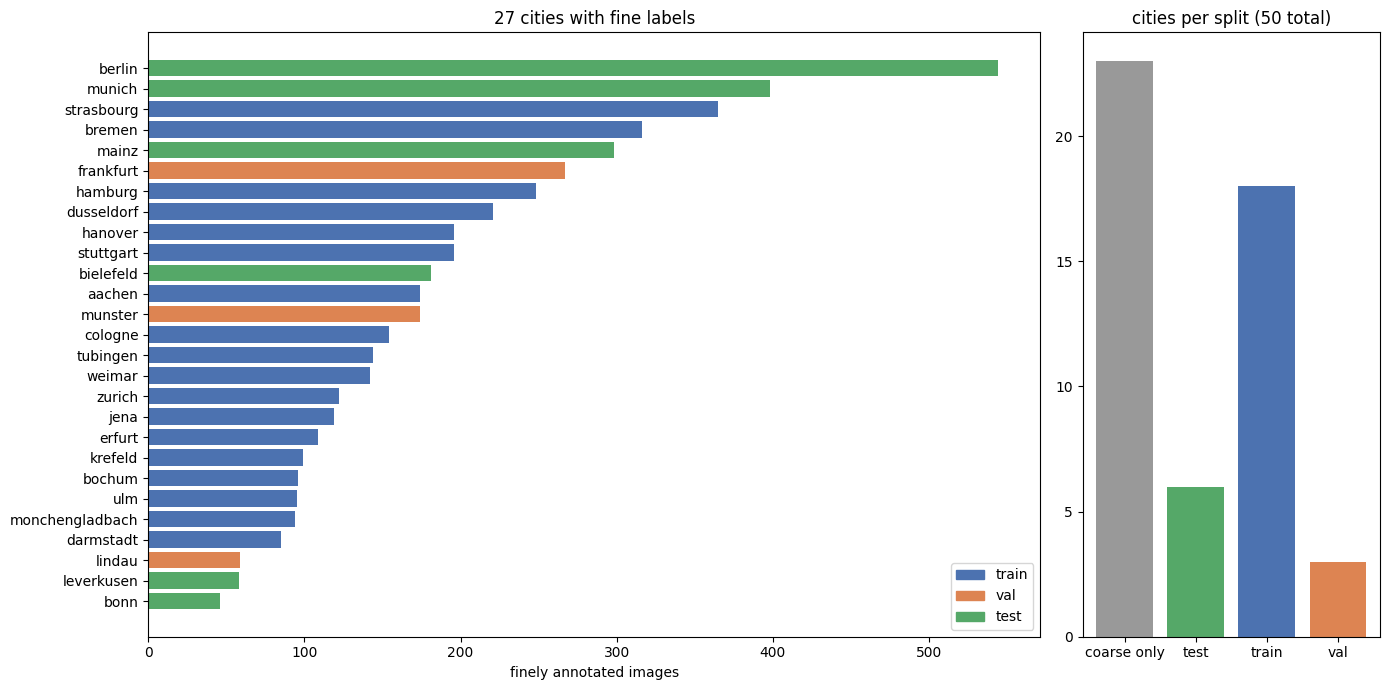

In [8]:
fine = {
    "train": {"strasbourg": 365, "bremen": 316, "hamburg": 248, "dusseldorf": 221, "hanover": 196,
              "stuttgart": 196, "aachen": 174, "cologne": 154, "tubingen": 144, "weimar": 142,
              "zurich": 122, "jena": 119, "erfurt": 109, "krefeld": 99, "bochum": 96, "ulm": 95,
              "monchengladbach": 94, "darmstadt": 85},
    "val":   {"frankfurt": 267, "munster": 174, "lindau": 59},
    "test":  {"berlin": 544, "munich": 398, "mainz": 298, "bielefeld": 181, "leverkusen": 58, "bonn": 46},
}
coarse_only = ["augsburg", "bad-honnef", "bamberg", "bayreuth", "dortmund", "dresden", "duisburg",
               "erlangen", "freiburg", "heidelberg", "heilbronn", "karlsruhe", "konigswinter", "konstanz",
               "mannheim", "muhlheim-ruhr", "nuremberg", "oberhausen", "saarbrucken", "schweinfurt",
               "troisdorf", "wuppertal", "wurzburg"]
country = {"zurich": "Switzerland", "strasbourg": "France"}

rows = [(c, s, n) for s, d in fine.items() for c, n in d.items()] + [(c, "coarse only", 0) for c in coarse_only]
cities = pd.DataFrame(rows, columns=["city", "split", "fine_images"])
cities["country"] = cities.city.map(country).fillna("Germany")
print(cities.groupby("country").size().to_string(), "\n")

colors = {"train": "#4c72b0", "val": "#dd8452", "test": "#55a868"}
f = cities[cities.fine_images > 0].sort_values("fine_images")
fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [3, 1]})
ax[0].barh(f.city, f.fine_images, color=f.split.map(colors))
ax[0].legend(handles=[mpatches.Patch(color=v, label=k) for k, v in colors.items()])
ax[0].set_xlabel("finely annotated images"); ax[0].set_title("27 cities with fine labels")
split_counts = cities.groupby("split").size()
ax[1].bar(split_counts.index, split_counts.values, color=["#999999", "#55a868", "#4c72b0", "#dd8452"])
ax[1].set_title("cities per split (50 total)")
plt.tight_layout(); plt.show()

The samples below are real Cityscapes images with their fine labels: 8 images from Aachen, from the free `cityscapes8` sample by Ultralytics. The masks store the original label ids (0-33), which are mapped to the 19 train classes. Black means void.

8 Cityscapes images


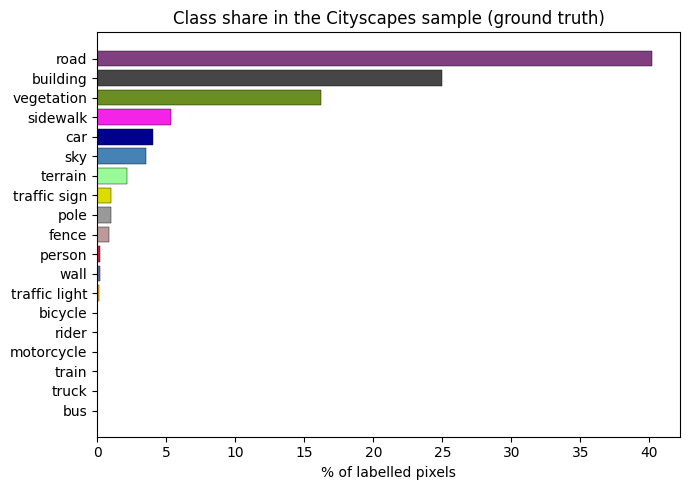

In [9]:
CS_DIR = "/content/cityscapes8"
if not os.path.isdir(CS_DIR):
    urllib.request.urlretrieve("https://github.com/ultralytics/assets/releases/download/v0.0.0/cityscapes8.zip", "cs8.zip")
    zipfile.ZipFile("cs8.zip").extractall("/content")

LUT = np.full(256, IGNORE, np.uint8)   # official labelId -> trainId
for lid, tid in {7: 0, 8: 1, 11: 2, 12: 3, 13: 4, 17: 5, 19: 6, 20: 7, 21: 8, 22: 9, 23: 10, 24: 11,
                 25: 12, 26: 13, 27: 14, 28: 15, 31: 16, 32: 17, 33: 18}.items():
    LUT[lid] = tid

cs = []
for p in sorted(glob.glob(f"{CS_DIR}/images/*/*.png")):
    img = np.array(Image.open(p).convert("RGB"))
    gt = LUT[np.array(Image.open(p.replace("/images/", "/masks/")))]
    img, gt = cv2.resize(img, (1024, 512)), cv2.resize(gt, (1024, 512), interpolation=cv2.INTER_NEAREST)
    cs.append(dict(name=os.path.basename(p)[:-4], img=img, gt=gt))
print(len(cs), "Cityscapes images")

gt_share = pd.Series(np.sum([np.bincount(d["gt"][d["gt"] != IGNORE], minlength=len(CLASSES)) for d in cs], 0), index=CLASSES)
gt_share = (gt_share / gt_share.sum() * 100)[CITYSCAPES]
s = gt_share.sort_values()
plt.figure(figsize=(7, 5))
plt.barh(s.index, s.values, color=[PALETTE[ID[c]] / 255 for c in s.index], edgecolor="k", linewidth=0.3)
plt.xlabel("% of labelled pixels"); plt.title("Class share in the Cityscapes sample (ground truth)")
plt.tight_layout(); plt.show()

Road, building, vegetation and sidewalk cover most of the pixels. People and vehicles are a small share, and motorcycles are almost absent. The full dataset shows the same pattern.

## 3. Stage 1: Cityscapes images

All three types on the Cityscapes samples. Aachen is a training city, so the semantic score is optimistic. On the official validation set SegFormer-B2 reaches about 81% mIoU, and Mask2Former Swin-L about 66% PQ (from the papers). This sample has no instance IDs, so instance and panoptic results are shown but not scored here.

semantic, 19 classes: mIoU 65.5%   pixel accuracy 97.3%
road          98.9
person        66.8
car           91.6
motorcycle     0.0
bus            NaN
truck          0.0


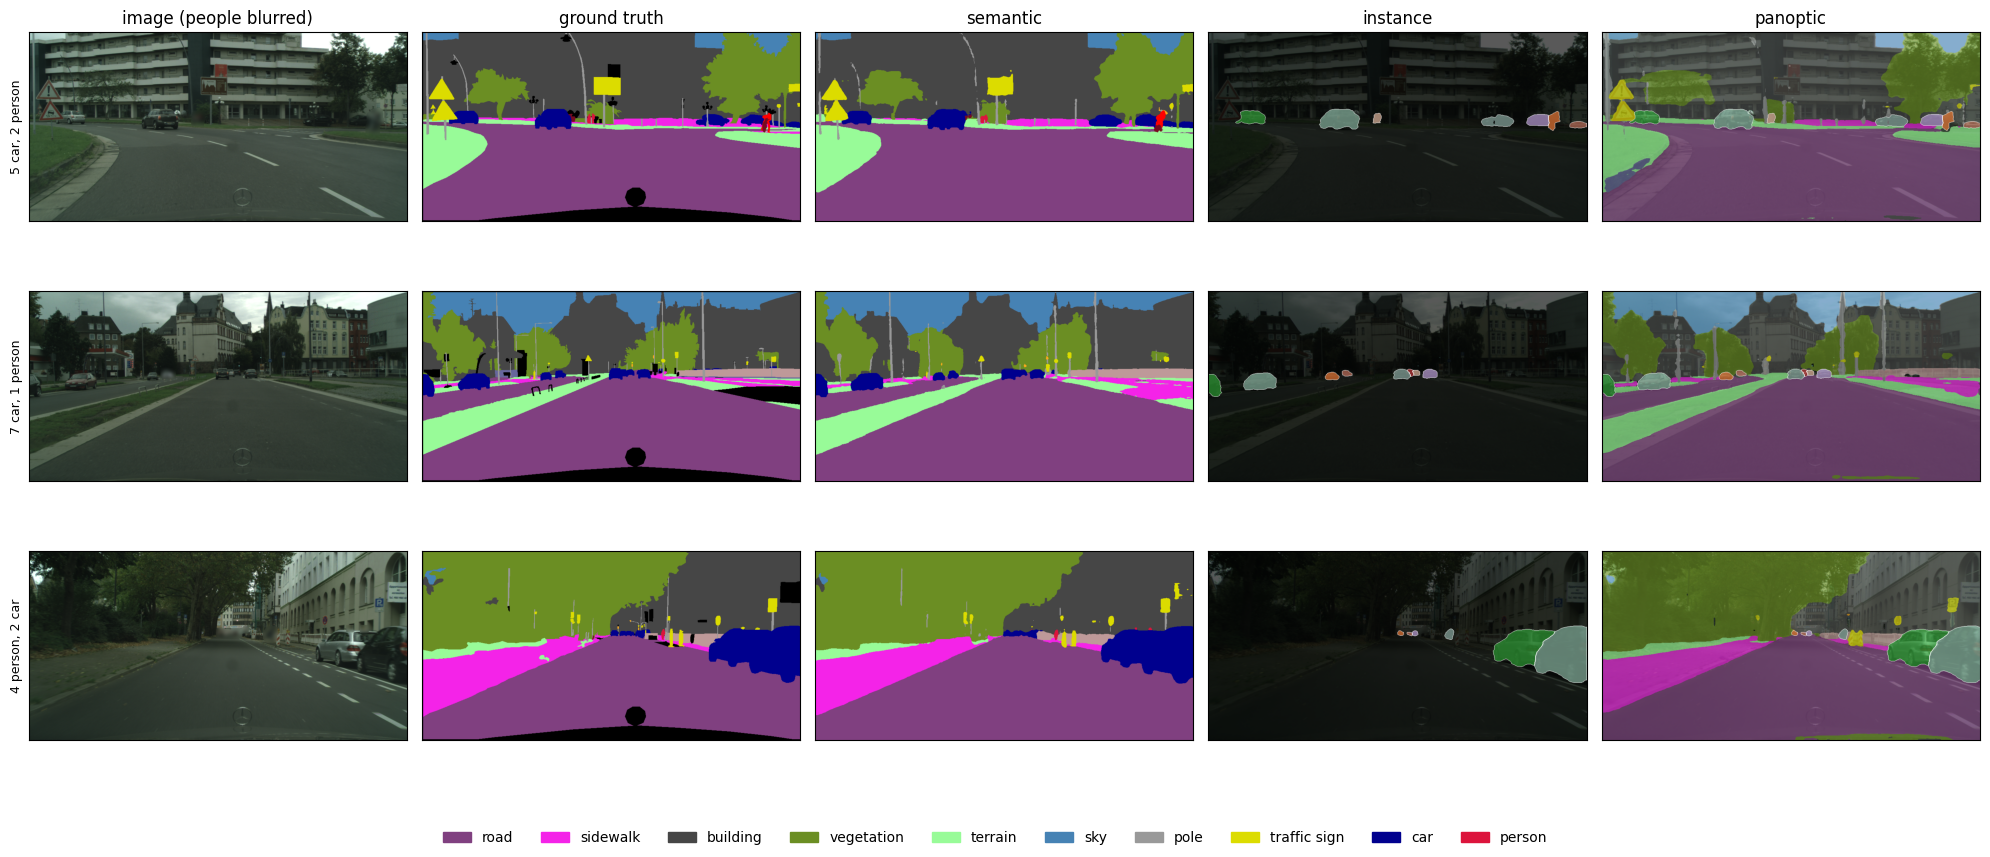

In [10]:
for d in cs:
    d["sem"] = semantic(base, d["img"], merge_rider=False)
    d["pan"] = panoptic(d["img"])
    d["safe"] = anon(d["img"], d["gt"], d["sem"], segs=d["pan"])

cs_iou19, cs_acc = iou_scores([d["sem"] for d in cs], [d["gt"] for d in cs], CITYSCAPES)
print(f"semantic, 19 classes: mIoU {np.nanmean(cs_iou19):.1f}%   pixel accuracy {cs_acc:.1f}%")

merge = lambda a: np.where(a == ID["rider"], ID["person"], a).astype(np.uint8)
cs_iou, _ = iou_scores([merge(d["sem"]) for d in cs], [merge(d["gt"]) for d in cs], [c for c in EVAL if c != "rickshaw"])
print(cs_iou.round(1).to_string())

show_grid([[d["safe"], colorize(d["gt"]), colorize(d["sem"]), draw(d["safe"], d["pan"], "instance"),
            draw(d["safe"], d["pan"], "panoptic")] for d in cs[:3]],
          ["image (people blurred)", "ground truth", "semantic", "instance", "panoptic"], 4,
          ["road", "sidewalk", "building", "vegetation", "terrain", "sky", "pole", "traffic sign", "car", "person"],
          [count_str(d["pan"]) for d in cs[:3]])

- **Semantic:** road (about 99% IoU) and cars (about 92%) are almost exact. Errors are mainly thin poles, signs and object edges. Motorcycle and truck score 0 because they cover only a few pixels in these 8 images: a mistake on a few pixels decides the score.
- **Instance:** each parked car and each person gets its own mask and colour, so the objects can be counted (shown on the left of each row).
- **Panoptic:** combines both views, with background classes in their class colour and each object in its own colour.

## 4. Karachi data, privacy and annotation

**Photos.** Phone photos of Karachi roads, taken from footbridges, a high floor and inside vehicles, plus openly available web photos (Pexels, Wikimedia Commons). Of the 11 labelled photos, 2 are phone photos and 9 are web photos.

**Privacy.**
- Photos were taken in public places, of traffic in general, with no close-ups of people.
- EXIF data (including GPS) is removed when loading.
- People found by the labels or the models are blurred before any image is shown. Number plates are not detected, so they are not blurred, and a person a model misses stays visible.
- The photos are used only for this coursework.

**Annotation.** Labels were drawn by hand in makesense.ai with the polygon tool and exported as COCO JSON. Each polygon is one object, so the same labels give semantic ground truth (class per pixel) and instance/panoptic ground truth (one segment per object).

| label | covers |
|---|---|
| road | drivable surface (one stuff segment per photo) |
| person | pedestrians and people on bikes |
| car | cars, vans |
| motorcycle | all motorbikes, moving or parked |
| rickshaw | auto rickshaws and chingchis (new class) |
| bus | buses, minibuses |
| truck | trucks, loaders, pickups, tankers |
| ignore | dense far-away clusters, dug-up road, construction machines (left out of scoring) |
| sky, building, vegetation, sidewalk (optional) | scored automatically when labelled |

Every visible object of these classes was outlined in each labelled photo. The exception is the traffic-jam photo, where only some objects were outlined. For that photo, only the outlined areas are scored (listed in `PARTIAL_LABELS`). Sky, buildings and trees were not labelled and are not scored. Polygons are drawn road first, then large objects, then small ones, then `ignore`, so overlaps keep the nearer object.

11 labelled photos, 1 partially labelled
scored classes: ['road', 'person', 'car', 'motorcycle', 'rickshaw', 'bus', 'truck']


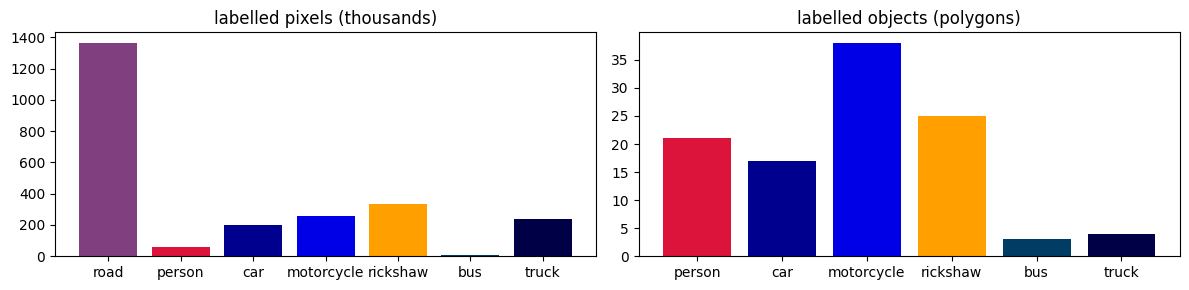

In [11]:
LABEL_MAP = {"road": "road", "person": "person", "people": "person", "rider": "person", "car": "car", "van": "car",
             "motorcycle": "motorcycle", "motorbike": "motorcycle", "bike": "motorcycle", "rickshaw": "rickshaw",
             "qingqi": "rickshaw", "chingchi": "rickshaw", "auto rickshaw": "rickshaw", "bus": "bus",
             "minibus": "bus", "truck": "truck", "pickup": "truck", "loader": "truck", "tanker": "truck", "ignore": "ignore",
             "sidewalk": "sidewalk", "footpath": "sidewalk", "building": "building", "vegetation": "vegetation",
             "tree": "vegetation", "sky": "sky", "terrain": "terrain"}
STUFF_LABELS = ["road", "sidewalk", "building", "vegetation", "sky", "terrain"]

coco = json.load(open(LABELS_JSON))
cat = {c["id"]: c["name"].strip().lower() for c in coco["categories"]}
anns = {}
for a in coco["annotations"]:
    anns.setdefault(a["image_id"], []).append(a)

def rasterise(info, shape):
    # returns class map, instance-id map, {instance id: class} and the drawn area
    h, w = shape
    sx, sy = w / info["width"], h / info["height"]
    gt = np.full((h, w), OTHER, np.uint8)
    inst = np.zeros((h, w), np.int32)
    drawn = np.zeros((h, w), bool)
    items = []
    for a in anns.get(info["id"], []):
        name = LABEL_MAP.get(cat.get(a["category_id"], ""))
        if name and isinstance(a.get("segmentation"), list):
            order = 0 if name in STUFF_LABELS else (2 if name == "ignore" else 1)
            items.append((order, -a.get("area", 0), name, a["segmentation"]))
    segments, next_id = {}, 2
    for _, _, name, segm in sorted(items, key=lambda t: t[:2]):
        layer = np.zeros((h, w), np.uint8)
        for poly in segm:
            pts = (np.array(poly, np.float32).reshape(-1, 2) * [sx, sy]).round().astype(np.int32)
            cv2.fillPoly(layer, [pts], 1)
        layer = layer.astype(bool)
        drawn |= layer
        if name == "ignore":
            gt[layer] = IGNORE; inst[layer] = 0
        elif name in STUFF_LABELS:   # one segment per stuff class
            gt[layer] = ID[name]; inst[layer] = 1000 + ID[name]; segments[1000 + ID[name]] = ID[name]
        else:
            gt[layer] = ID[name]; inst[layer] = next_id; segments[next_id] = ID[name]; next_id += 1
    segments = {k: v for k, v in segments.items() if (inst == k).any()}   # drop fully covered ones
    return gt, inst, segments, drawn

data = []
for info in coco["images"]:
    path = os.path.join(IMG_DIR, os.path.basename(info["file_name"]))
    if not os.path.exists(path):
        continue
    img = load_clean(path)
    gt, inst, segments, drawn = rasterise(info, img.shape[:2])
    if drawn.any():
        data.append(dict(name=os.path.basename(path), img=img, gt=gt, inst=inst, segments=segments, drawn=drawn))
# photos where only some objects were outlined: everything not outlined is left out of scoring,
# so correct predictions on unlabelled objects are not counted as mistakes
PARTIAL_LABELS = ["66ef4913f2b9e.jpg"]
DROP_PHOTOS = []                          # photos to leave out completely
data = [d for d in data if d["name"] not in DROP_PHOTOS]
for d in data:
    if d["name"] in PARTIAL_LABELS:
        d["gt"][d["gt"] == OTHER] = IGNORE
print(len(data), "labelled photos,", sum(d["name"] in PARTIAL_LABELS for d in data), "partially labelled")

# stuff classes beyond road are scored only if they were labelled
EXTRA = [c for c in STUFF_LABELS[1:] if any((d["gt"] == ID[c]).any() for d in data)]
EVAL = EVAL + [c for c in EXTRA if c not in EVAL]
print("scored classes:", EVAL)

obj = Counter(CLASSES[c] for d in data for c in d["segments"].values() if c not in [ID[x] for x in STUFF_LABELS])
px = pd.Series(np.sum([np.bincount(d["gt"][d["gt"] < len(CLASSES)], minlength=len(CLASSES)) for d in data], 0), index=CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].bar(EVAL, px[EVAL] / 1e3, color=[PALETTE[ID[c]] / 255 for c in EVAL]); ax[0].set_title("labelled pixels (thousands)")
ax[1].bar(OBJECTS, [obj[c] for c in OBJECTS], color=[PALETTE[ID[c]] / 255 for c in OBJECTS]); ax[1].set_title("labelled objects (polygons)")
plt.tight_layout(); plt.show()

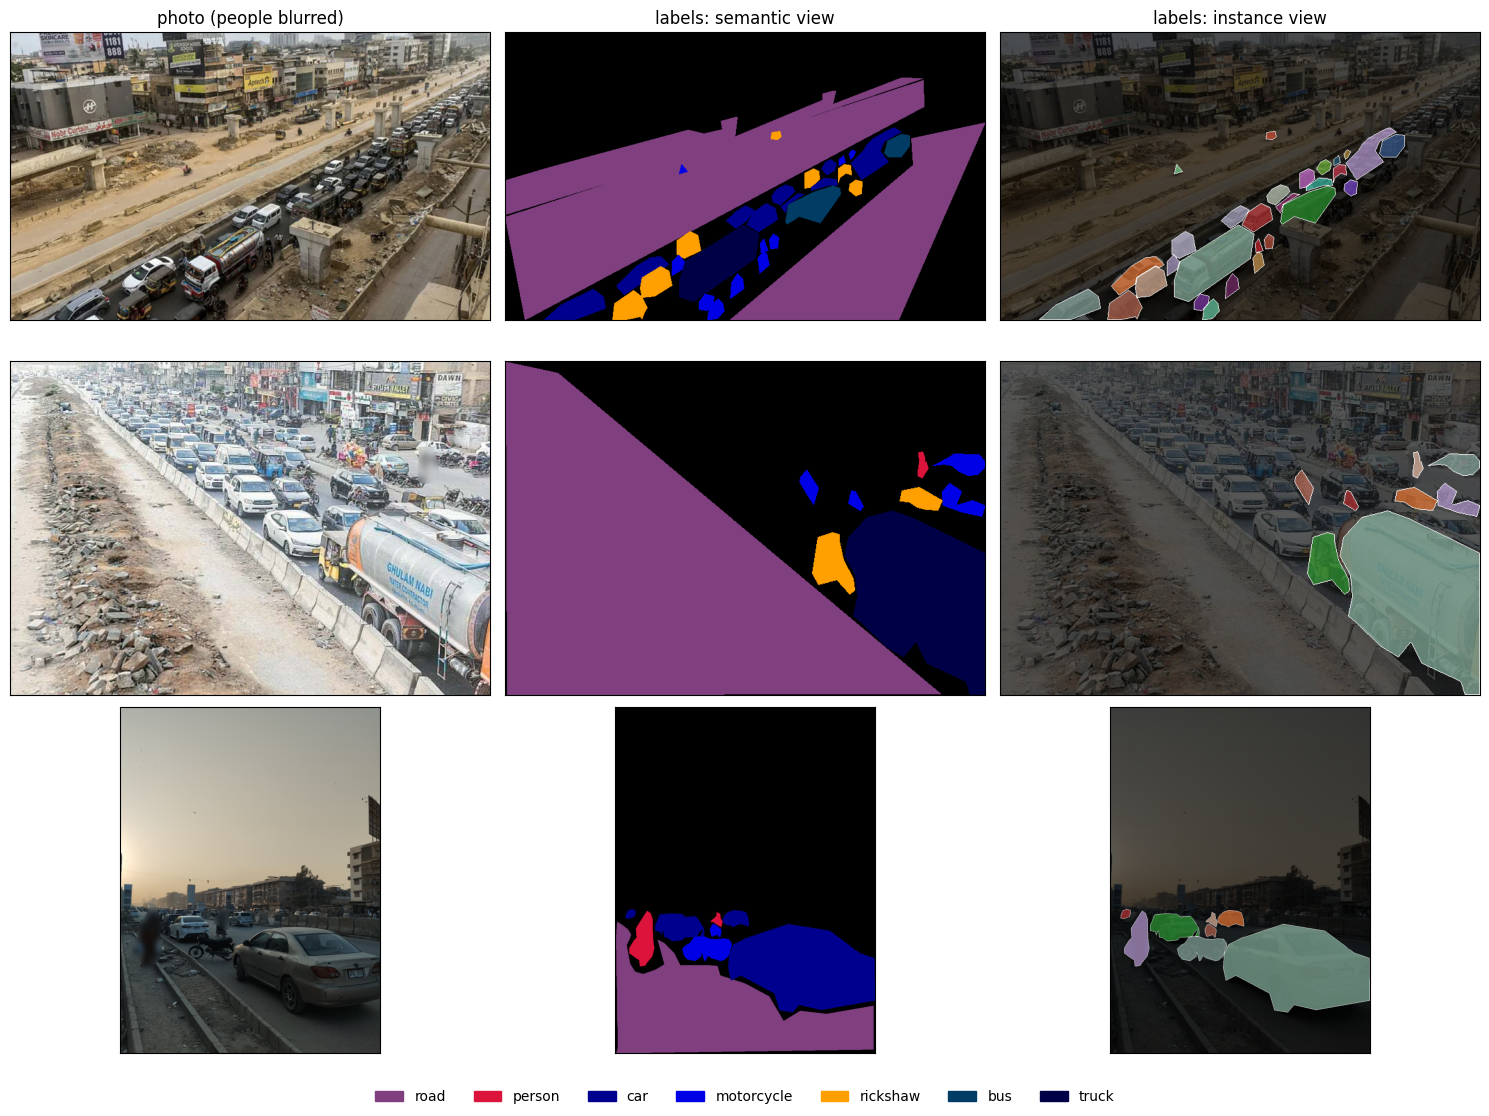

In [12]:
def gt_semantic_view(d):
    return colorize(np.where(d["gt"] == OTHER, IGNORE, d["gt"]))

def gt_segments(d):
    return [dict(mask=d["inst"] == k, cls=c) for k, c in d["segments"].items()]

for d in data:
    d["safe"] = anon(d["img"], d["gt"])

show_grid([[d["safe"], gt_semantic_view(d), draw(d["safe"], gt_segments(d), "instance")] for d in data[:3]],
          ["photo (people blurred)", "labels: semantic view", "labels: instance view"], 5, EVAL)

The same polygons give both views: each class in its own colour (semantic), or each object in its own colour (instance). Bus has very few labelled objects, so its scores are unreliable.

**Train/test split.** Near-identical photos are grouped (image correlation > 0.9), and each group goes wholly into train or test, so no test photo has a near-copy in training. About a third of the photos go to test (4 of 11).

In [13]:
def thumb(img):
    t = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (32, 32)).astype(np.float32).ravel()
    return (t - t.mean()) / (t.std() + 1e-6)

th = [thumb(d["img"]) for d in data]
parent = list(range(len(data)))
def find(i):
    while parent[i] != i:
        i = parent[i]
    return i
for i in range(len(data)):
    for j in range(i + 1, len(data)):
        if th[i] @ th[j] / len(th[i]) > 0.9:
            parent[find(j)] = find(i)
groups = {}
for i in range(len(data)):
    groups.setdefault(find(i), []).append(i)
groups = list(groups.values())
random.Random(SEED).shuffle(groups)

test_idx, train_idx = [], []
for g in groups:
    (test_idx if len(test_idx) < 0.3 * len(data) else train_idx).extend(g)
train_items, test_items = [data[i] for i in train_idx], [data[i] for i in test_idx]
print("train:", len(train_items), "photos | test:", len(test_items), "photos")
print("test photos:", [d["name"] for d in test_items])

train: 7 photos | test: 4 photos
test photos: ['pexels-aniquah-riaz-2165265882-40618005.jpg', 'pexels-hamza-awan-1282073526-40084585.jpg', '66ef4913f2b9e.jpg', 'WhatsApp Image 2026-11-05 at 12.21.51 AM (1).jpeg']


## 5. Stage 2: Karachi without fine-tuning

The original Cityscapes models are run on the Karachi test photos and scored against the hand labels.
- **Semantic:** IoU per class.
- **Instance:** precision and recall per class. A predicted object counts as correct when it overlaps a labelled object with IoU > 0.5.
- **Panoptic:** PQ = SQ x RQ. SQ is how well the matched masks fit, and RQ is how many objects are found correctly.

The averages use the 6 classes with labelled objects in the test photos, so bus is left out. Using one class set keeps the before and after scores comparable.

In [14]:
for d in data:
    d["sem_before"] = semantic(base, d["img"])
    d["pan_before"] = panoptic(d["img"])
    d["safe"] = anon(d["img"], d["gt"], d["sem_before"], segs=d["pan_before"])

test_gt = [d["gt"] for d in test_items]
sem_before, sem_acc_before = iou_scores([d["sem_before"] for d in test_items], test_gt, EVAL)
pq_before = panoptic_quality([d["pan_before"] for d in test_items], test_items, EVAL)

# means use the classes with at least one labelled object in the test photos, before and after
scored = pq_before.index[pq_before.GT > 0].tolist()
scored_objects = [c for c in OBJECTS if c in scored]

print(f"SEMANTIC   mIoU {sem_before[scored].mean():.1f}%   pixel accuracy {sem_acc_before:.1f}%")
print(sem_before.round(1).to_string(), "\n")
print("INSTANCE (objects, IoU > 0.5)")
print(pq_before.loc[OBJECTS, ["GT", "predicted", "TP", "precision", "recall"]].round(1).to_string(), "\n")
means = pq_before.loc[scored]
print(f"PANOPTIC   PQ {means.PQ.mean():.1f}  SQ {means.SQ.mean():.1f}  RQ {means.RQ.mean():.1f}")
print(pq_before[["PQ", "SQ", "RQ"]].round(1).to_string())

SEMANTIC   mIoU 39.1%   pixel accuracy 74.1%
road          88.7
person        47.2
car           40.0
motorcycle    39.4
rickshaw       0.0
bus            0.0
truck         19.5 

INSTANCE (objects, IoU > 0.5)
             GT  predicted   TP  precision  recall
person      5.0        7.0  3.0       42.9    60.0
car         4.0       18.0  3.0       16.7    75.0
motorcycle  6.0        1.0  1.0      100.0    16.7
rickshaw    5.0        0.0  0.0        NaN     0.0
bus         0.0        0.0  0.0        NaN     NaN
truck       2.0        3.0  1.0       33.3    50.0 

PANOPTIC   PQ 30.8  SQ 64.6  RQ 38.6
              PQ    SQ    RQ
road        77.4  90.3  85.7
person      30.1  60.3  50.0
car         19.7  72.1  27.3
motorcycle  21.5  75.1  28.6
rickshaw     0.0   0.0   0.0
bus          NaN   NaN   NaN
truck       35.9  89.8  40.0


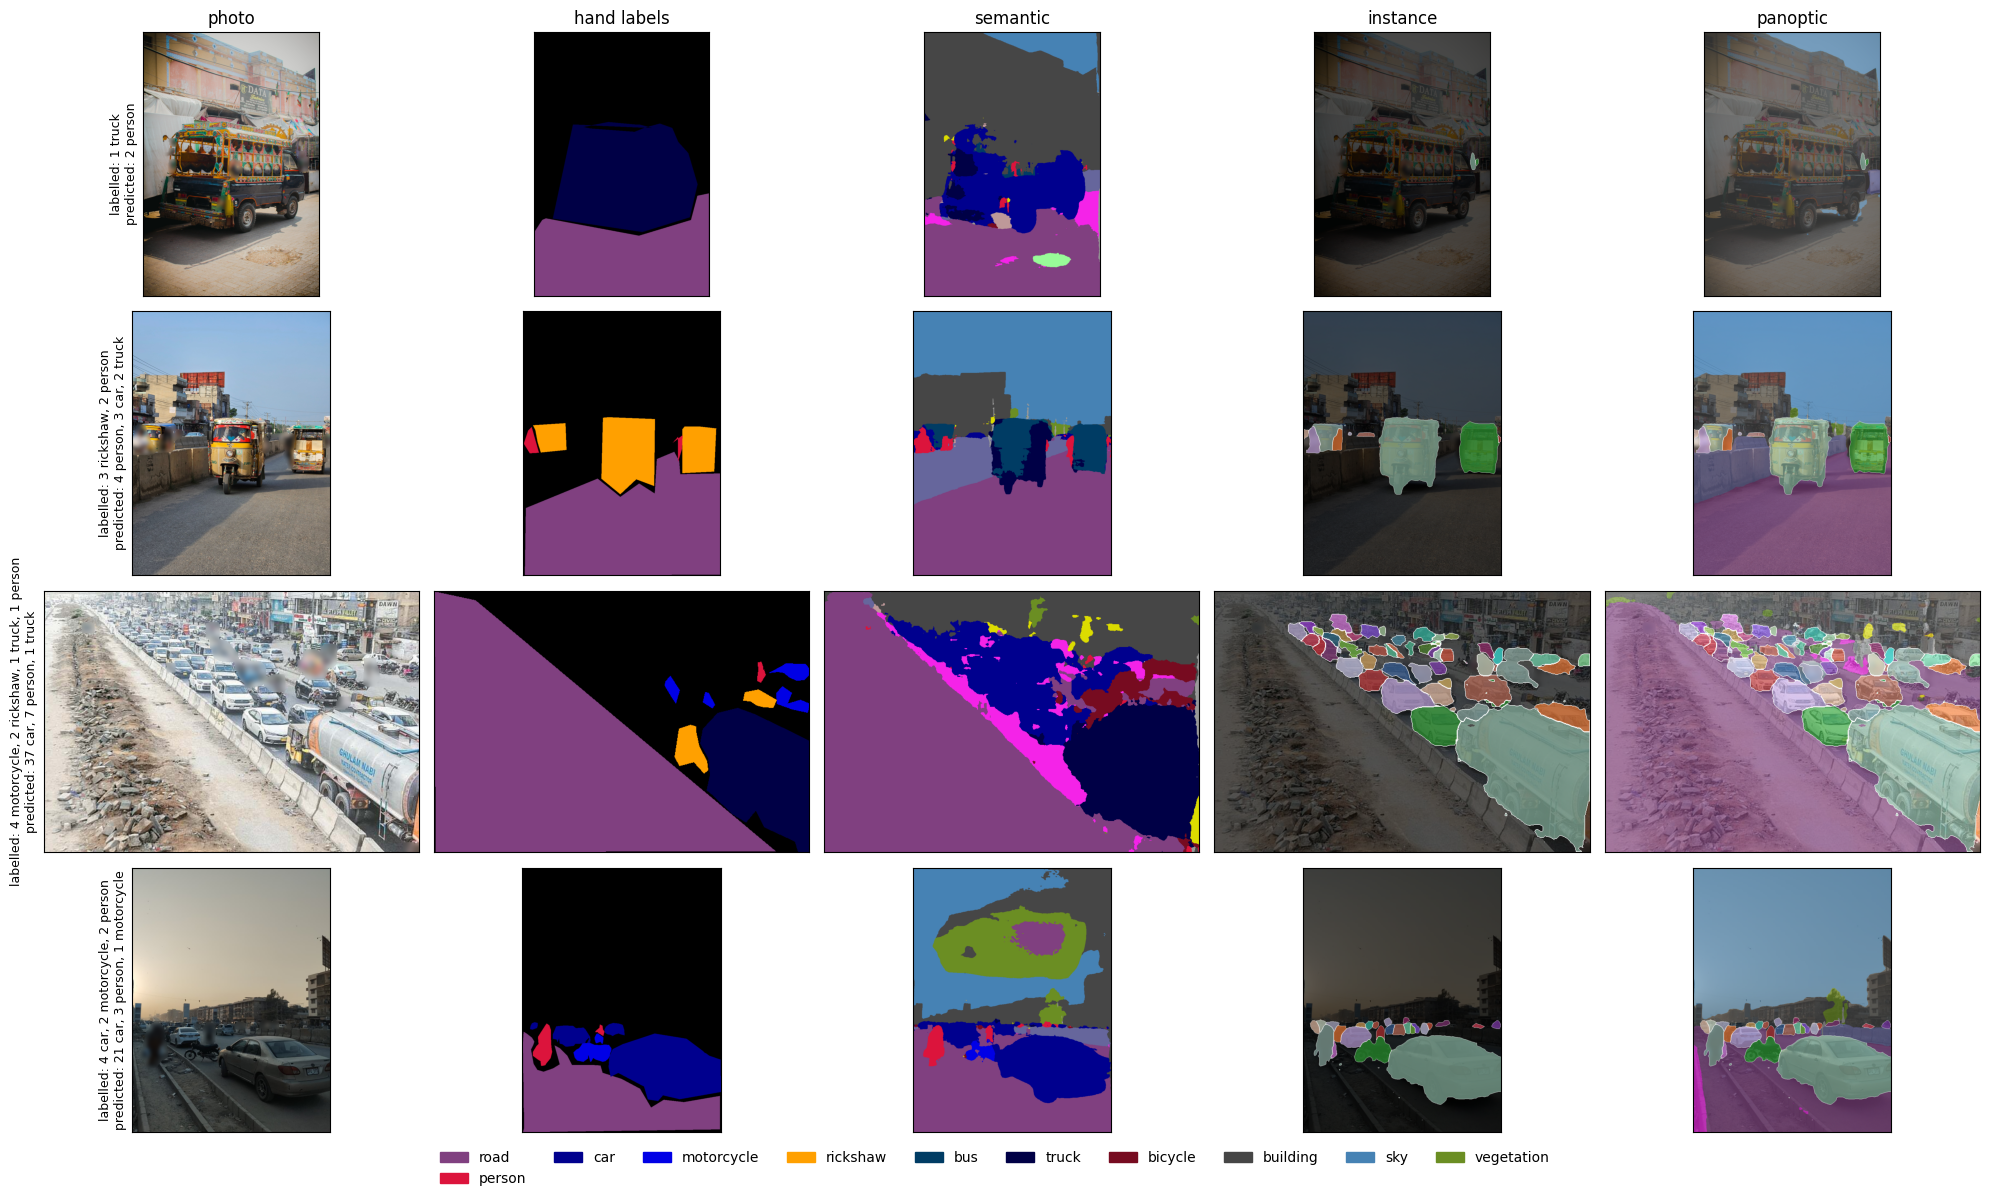

In [15]:
show_grid([[d["safe"], gt_semantic_view(d), colorize(d["sem_before"]), draw(d["safe"], d["pan_before"], "instance"),
            draw(d["safe"], d["pan_before"], "panoptic")] for d in test_items],
          ["photo", "hand labels", "semantic", "instance", "panoptic"], 4,
          EVAL + ["bicycle", "building", "sky", "vegetation"],
          [f"labelled: {count_str(gt_segments(d))}\npredicted: {count_str(d['pan_before'])}" for d in test_items])

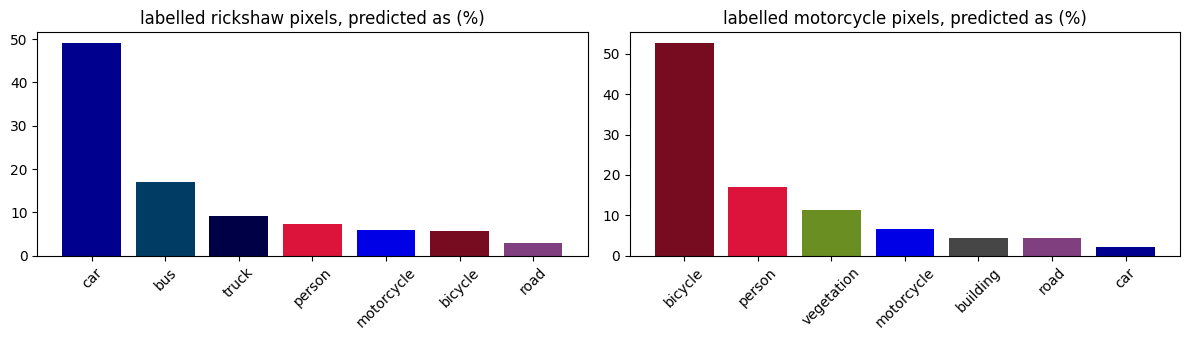

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, cls in zip(ax, ["rickshaw", "motorcycle"]):
    s = confusion_of([d["sem_before"] for d in data], [d["gt"] for d in data], cls)
    a.bar(s.index, s.values, color=[PALETTE[ID[c]] / 255 for c in s.index])
    a.set_title(f"labelled {cls} pixels, predicted as (%)"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Comments (without fine-tuning)**
- **Semantic:** road is segmented well (about 89% IoU), but vehicles are not. With no rickshaw class, rickshaws are mostly called car (about half of their pixels), then bus and truck. This chart uses all 11 labelled photos, because the original model has seen none of them. About half of the motorcycle pixels are called bicycle, and many go to person.
- **Instance:** rickshaws can only be found under a wrong class, so their recall is 0. Rows of parked motorbikes often merge into a few large masks or are missed, so the motorcycle count falls well below the labelled count.
- **Panoptic:** PQ combines both problems. Road scores high, and the vehicle classes pull the mean down.

## 6. Fine-tuning

**What is fine-tuned.** SegFormer is fine-tuned on the training photos with a 20th class, `rickshaw`:
- **New class:** one extra output channel for `rickshaw`, starting from the average of the car and motorcycle weights.
- **Training targets:** hand labels where drawn. Elsewhere, the original model's prediction is used for background (sky, buildings, trees). Pixels where it predicted road, a vehicle or a person outside the hand labels are ignored.
- **Augmentation:** random scale, 512x512 crops, flips and brightness/contrast changes.
- **Optimiser:** AdamW, learning rate 6e-5 for the encoder and 6e-4 for the head, 2,000 iterations, batch size 2, and extra loss weight on rickshaw and motorcycle.

**How instance and panoptic use it.**
- **Masks:** Mask2Former still provides most object masks. It is not retrained, because that needs many more labelled photos and GPU memory.
- **Classes:** each Mask2Former vehicle takes the majority vehicle class of the fine-tuned semantic map inside it, so a "car" mask on a rickshaw becomes a rickshaw. People keep their class, because a mask over a rider could otherwise take the class of the bike.
- **Fragments:** rickshaw pieces that touch are merged into one object.
- **Missed objects:** rickshaw and motorcycle regions in the semantic map that no mask covers become new objects, so these masks come from the fine-tuned map, not Mask2Former.
- **Background:** road and the other background segments come from the fine-tuned map.

The fine-tuned model is loaded from Hugging Face (`HF_MODEL`) instead of being retrained. Nothing is saved to Drive. Set `RETRAIN = True` to train a new model, for example after changing the labels. It is kept only for this session; use the appendix to upload it to Hugging Face.

In [17]:
RETRAIN = False
ITERS, BATCH, CROP = 2000, 2, 512
SEM_THINGS = [ID[c] for c in ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]]

def make_target(d):
    t = semantic(base, d["img"], merge_rider=False)
    t[np.isin(t, SEM_THINGS)] = IGNORE
    for c in EVAL:   # classes outlined by hand: drop the old model's guesses outside the outlines
        if c in STUFF_LABELS:
            t[(t == ID[c]) & ~d["drawn"]] = IGNORE
    t[d["drawn"]] = np.where(d["gt"] == OTHER, IGNORE, d["gt"])[d["drawn"]]
    return t

def add_rickshaw(m):
    m = copy.deepcopy(m)
    old = m.decode_head.classifier
    new = nn.Conv2d(old.in_channels, len(CLASSES), 1).to(old.weight.device)
    with torch.no_grad():
        new.weight[:19], new.bias[:19] = old.weight, old.bias
        new.weight[19] = (old.weight[ID["car"]] + old.weight[ID["motorcycle"]]) / 2
        new.bias[19] = (old.bias[ID["car"]] + old.bias[ID["motorcycle"]]) / 2
    m.decode_head.classifier = new
    m.config.num_labels = len(CLASSES)
    m.config.id2label = dict(enumerate(CLASSES)); m.config.label2id = {c: i for i, c in enumerate(CLASSES)}
    return m

def sample(d):
    s = random.uniform(0.6, 1.25)
    h, w = int(d["img"].shape[0] * s), int(d["img"].shape[1] * s)
    img = cv2.resize(d["img"], (w, h))
    tgt = cv2.resize(d["target"], (w, h), interpolation=cv2.INTER_NEAREST)
    ph, pw = max(0, CROP - h), max(0, CROP - w)
    img = cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0)
    tgt = cv2.copyMakeBorder(tgt, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=IGNORE)
    for _ in range(10):  # prefer crops with the rare classes
        y, x = random.randint(0, img.shape[0] - CROP), random.randint(0, img.shape[1] - CROP)
        t = tgt[y:y + CROP, x:x + CROP]
        if np.isin(t, [ID["rickshaw"], ID["motorcycle"]]).any() or random.random() < 0.3:
            break
    im = img[y:y + CROP, x:x + CROP].astype(np.float32)
    if random.random() < 0.5:
        im, t = im[:, ::-1], t[:, ::-1]
    im = np.clip(im * random.uniform(0.75, 1.25) + random.uniform(-20, 20), 0, 255)
    return im.astype(np.uint8), np.ascontiguousarray(t)

def train_segformer(items, iters=ITERS, seed=SEED, log_every=400):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    for d in items:
        if "target" not in d:
            d["target"] = make_target(d)
    m = add_rickshaw(base).to(device)
    head = list(m.decode_head.parameters()); hid = {id(p) for p in head}
    opt = torch.optim.AdamW([{"params": [p for p in m.parameters() if id(p) not in hid], "lr": 6e-5},
                             {"params": head, "lr": 6e-4}], weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: (1 - i / iters) ** 0.9)
    scaler = torch.amp.GradScaler(enabled=device == "cuda")
    w = torch.ones(len(CLASSES), device=device); w[ID["rickshaw"]], w[ID["motorcycle"]] = 3.0, 2.0
    loss_fn = nn.CrossEntropyLoss(weight=w, ignore_index=IGNORE)
    losses = []
    for it in range(1, iters + 1):
        m.train()
        for mod in m.decode_head.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.eval()
        ims, ts = zip(*[sample(random.choice(items)) for _ in range(BATCH)])
        x = torch.cat([to_tensor(i) for i in ims]); y = torch.from_numpy(np.stack(ts)).long().to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
            out = F.interpolate(m(pixel_values=x).logits, size=y.shape[1:], mode="bilinear", align_corners=False)
            loss = loss_fn(out.float(), y)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if log_every and it % log_every == 0:
            print(f"iter {it}  loss {np.mean(losses[-log_every:]):.3f}")
    return m.eval(), losses

train_names = sorted(d["name"] for d in train_items)
SAVED_MODEL = "/content/segformer_karachi_rickshaw"   # temporary Colab copy, deleted when the session ends

if not RETRAIN:
    from huggingface_hub import snapshot_download
    path = snapshot_download(HF_MODEL)
    ft = SegformerForSemanticSegmentation.from_pretrained(path).to(device).eval()
    print("loaded fine-tuned model from Hugging Face")
    split_file = os.path.join(path, "train_photos.json")
    if not os.path.exists(split_file):
        print("WARNING: no record of this model's training photos. Set RETRAIN = True to rule out test photos in training.")
    elif json.load(open(split_file)) != train_names:
        print("WARNING: this model was trained on a different split. Set RETRAIN = True before quoting sections 7 and 8.")
else:
    ft, losses = train_segformer(train_items)
    ft.save_pretrained(SAVED_MODEL)
    json.dump(train_names, open(os.path.join(SAVED_MODEL, "train_photos.json"), "w"), indent=1)
    print("trained a new model (kept for this session only)")
    plt.figure(figsize=(6, 2.5)); plt.plot(pd.Series(losses).rolling(50).mean())
    plt.title("training loss"); plt.xlabel("iteration"); plt.show()


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

loaded fine-tuned model from Hugging Face


In [18]:
VEHICLE_IDS = [ID[c] for c in ["car", "truck", "bus", "train", "motorcycle", "bicycle", "rickshaw"]]

def relabel(segs, sem, min_frac=0.002, min_share=0.3):
    # Mask2Former masks + classes from the fine-tuned semantic map
    out, covered = [], np.zeros(sem.shape, bool)
    for s in segs:
        if s["cls"] not in THING_IDS:
            continue
        covered |= s["mask"]
        if s["cls"] == ID["person"]:          # fix 1: people keep their class
            out.append(s); continue
        v = sem[s["mask"]]; v = v[np.isin(v, VEHICLE_IDS)]
        new = int(np.bincount(v).argmax()) if v.size > min_share * s["mask"].sum() else s["cls"]
        out.append(dict(s, cls=new))

    # fix 2: rickshaw pieces that touch each other are one rickshaw
    rk = [o for o in out if o["cls"] == ID["rickshaw"]]
    if len(rk) > 1:
        union = np.any([o["mask"] for o in rk], axis=0).astype(np.uint8)
        n, lab = cv2.connectedComponents(cv2.dilate(union, np.ones((5, 5), np.uint8)))
        merged = [dict(mask=(lab == k) & union.astype(bool), cls=ID["rickshaw"],
                       score=max(o["score"] for o in rk if (o["mask"] & (lab == k)).any())) for k in range(1, n)]
        out = [o for o in out if o["cls"] != ID["rickshaw"]] + merged

    # fix 3: rickshaws and motorbikes the semantic model sees but Mask2Former missed become new objects
    for c in ["rickshaw", "motorcycle"]:
        left = ((sem == ID[c]) & ~covered).astype(np.uint8)
        n, lab, stats, _ = cv2.connectedComponentsWithStats(left)
        for k in range(1, n):
            if stats[k, cv2.CC_STAT_AREA] > min_frac * sem.size:
                m = lab == k
                out.append(dict(mask=m, cls=ID[c], score=0.5)); covered |= m

    for c in range(len(CITYSCAPES)):   # background segments from the fine-tuned map
        if c not in THING_IDS:
            m = (sem == c) & ~covered
            if m.any():
                out.append(dict(mask=m, cls=c, score=1.0))
    return out

## 7. Stage 3: Karachi with fine-tuning

The same test photos and the same metrics, now with the fine-tuned semantic model and the relabelled instance/panoptic output.

In [19]:
for d in data:
    d["sem_after"] = semantic(ft, d["img"])
    d["pan_after"] = relabel(d["pan_before"], d["sem_after"])
    d["safe"] = anon(d["img"], d["gt"], d["sem_before"], d["sem_after"], segs=d["pan_before"])

sem_after, sem_acc_after = iou_scores([d["sem_after"] for d in test_items], test_gt, EVAL)
pq_after = panoptic_quality([d["pan_after"] for d in test_items], test_items, EVAL)

print(f"SEMANTIC   mIoU {sem_after[scored].mean():.1f}%   pixel accuracy {sem_acc_after:.1f}%")
print(sem_after.round(1).to_string(), "\n")
print("INSTANCE (objects, IoU > 0.5)")
print(pq_after.loc[OBJECTS, ["GT", "predicted", "TP", "precision", "recall"]].round(1).to_string(), "\n")
means = pq_after.loc[scored]
print(f"PANOPTIC   PQ {means.PQ.mean():.1f}  SQ {means.SQ.mean():.1f}  RQ {means.RQ.mean():.1f}")
print(pq_after[["PQ", "SQ", "RQ"]].round(1).to_string())

SEMANTIC   mIoU 52.9%   pixel accuracy 81.9%
road          91.7
person        53.5
car           67.7
motorcycle    57.6
rickshaw      32.4
bus            0.0
truck         14.6 

INSTANCE (objects, IoU > 0.5)
             GT  predicted   TP  precision  recall
person      5.0        7.0  3.0       42.9    60.0
car         4.0       13.0  3.0       23.1    75.0
motorcycle  6.0        3.0  3.0      100.0    50.0
rickshaw    5.0       11.0  3.0       27.3    60.0
bus         0.0        1.0  0.0        0.0     NaN
truck       2.0        1.0  1.0      100.0    50.0 

PANOPTIC   PQ 46.5  SQ 76.0  RQ 59.4
              PQ    SQ     RQ
road        92.1  92.1  100.0
person      30.1  60.3   50.0
car         25.5  72.1   35.3
motorcycle  42.2  63.3   66.7
rickshaw    29.3  78.2   37.5
bus          0.0   0.0    0.0
truck       59.9  89.8   66.7


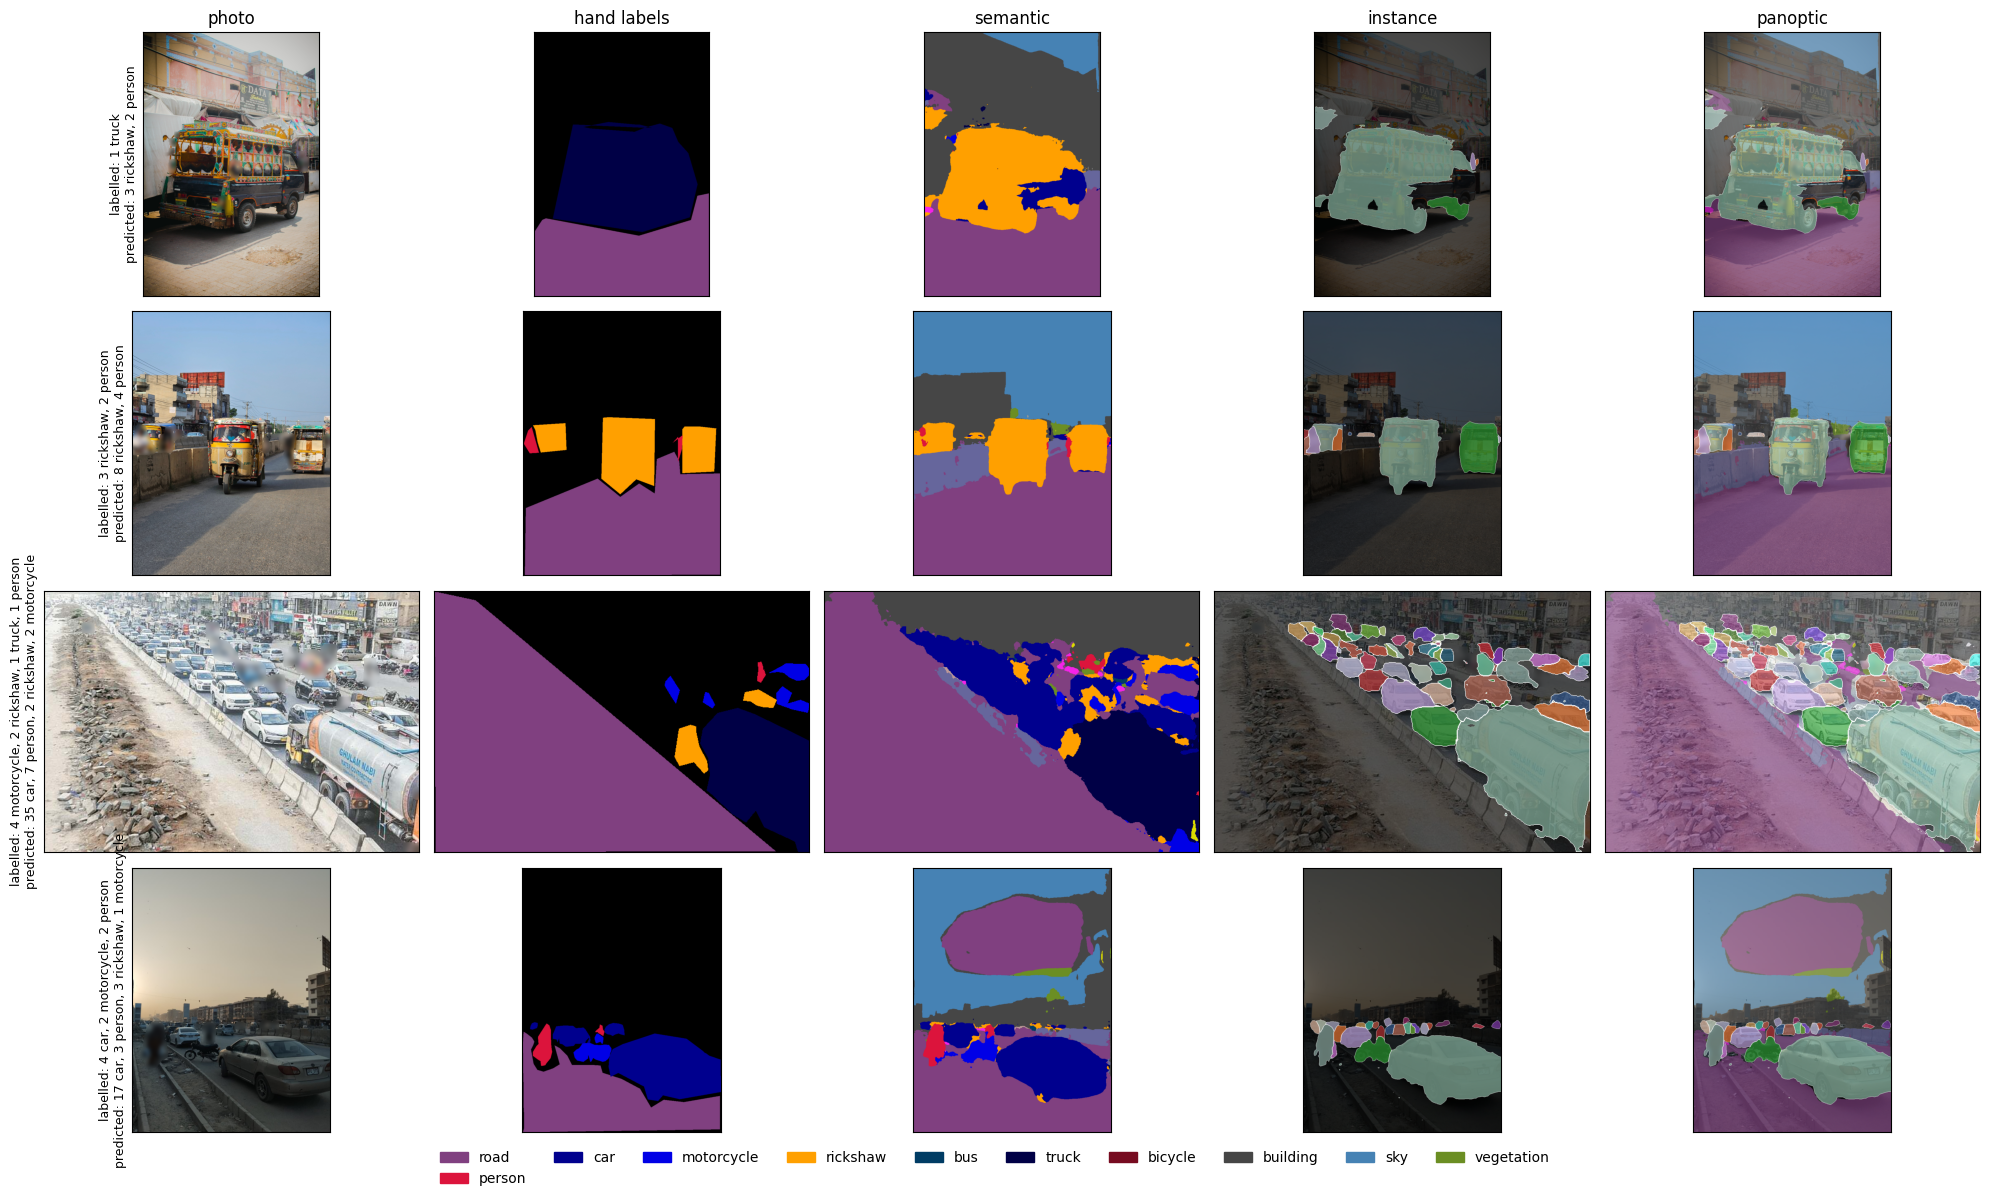

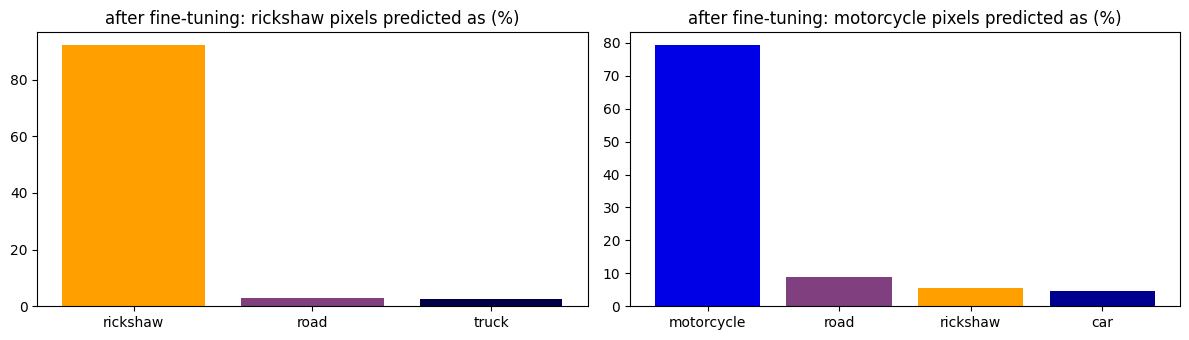

In [20]:
show_grid([[d["safe"], gt_semantic_view(d), colorize(d["sem_after"]), draw(d["safe"], d["pan_after"], "instance"),
            draw(d["safe"], d["pan_after"], "panoptic")] for d in test_items],
          ["photo", "hand labels", "semantic", "instance", "panoptic"], 4,
          EVAL + ["bicycle", "building", "sky", "vegetation"],
          [f"labelled: {count_str(gt_segments(d))}\npredicted: {count_str(d['pan_after'])}" for d in test_items])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, cls in zip(ax, ["rickshaw", "motorcycle"]):
    s = confusion_of([d["sem_after"] for d in test_items], test_gt, cls)
    a.bar(s.index, s.values, color=[PALETTE[ID[c]] / 255 for c in s.index])
    a.set_title(f"after fine-tuning: {cls} pixels predicted as (%)")
plt.tight_layout(); plt.show()

**Comments (with fine-tuning)**
- **Semantic:** mean IoU rose from about 39% to about 53%. Rickshaw went from 0 to 32%, car from 40% to 68%, and motorcycle from 39% to 58%. Parked motorbikes are no longer called bicycles. Two errors remain: the decorated Suzuki loader is called rickshaw (truck drops from 20% to 15%), and the hazy sky in the sunset photo is now predicted as road. Sky was not labelled, and with only 7 training photos the model overfits to road-like textures.
- **Instance and panoptic:** only the semantic model is trained, so these improve through better classes and the extra masks taken from the fine-tuned map. A first version of the relabelling showed three problems, which the three fixes in section 6 target:
  - **People lost:** people were relabelled as vehicles.
  - **Rickshaws split:** one rickshaw was often split into several pieces.
  - **Motorbikes missed:** Mask2Former drew no mask for most parked motorbikes.
- **What relabelling can't fix:** objects whose masks are wrong or merged. Rickshaws are still over-predicted (11 predicted for 5 labelled), and 3 of the 6 motorbikes are still missed.

**Finding: fine-tuning the semantic model transfers only partly to instance and panoptic segmentation.** Instance and panoptic output needs two things: a mask around each object, and a class for that mask. Fine-tuning improved the classes, because they now come from the fine-tuned semantic model. Most masks did not change, because they still come from Mask2Former trained on Cityscapes. Where the problem was the class (rickshaws), recall rose from 0 to 60%. Where the problem was a missing mask (parked motorbikes), the masks added from the semantic map raised recall from 17% to 50%, but half are still missed.


## 8. Comparison: without vs with fine-tuning

                          without fine-tuning  with fine-tuning  change
semantic: mIoU                           39.1              52.9    13.8
semantic: pixel accuracy                 74.1              81.9     7.8
instance: precision                      38.6              58.6    20.0
instance: recall                         40.3              59.0    18.7
panoptic: PQ                             30.8              46.5    15.7
panoptic: SQ                             64.6              76.0    11.4
panoptic: RQ                             38.6              59.4    20.8


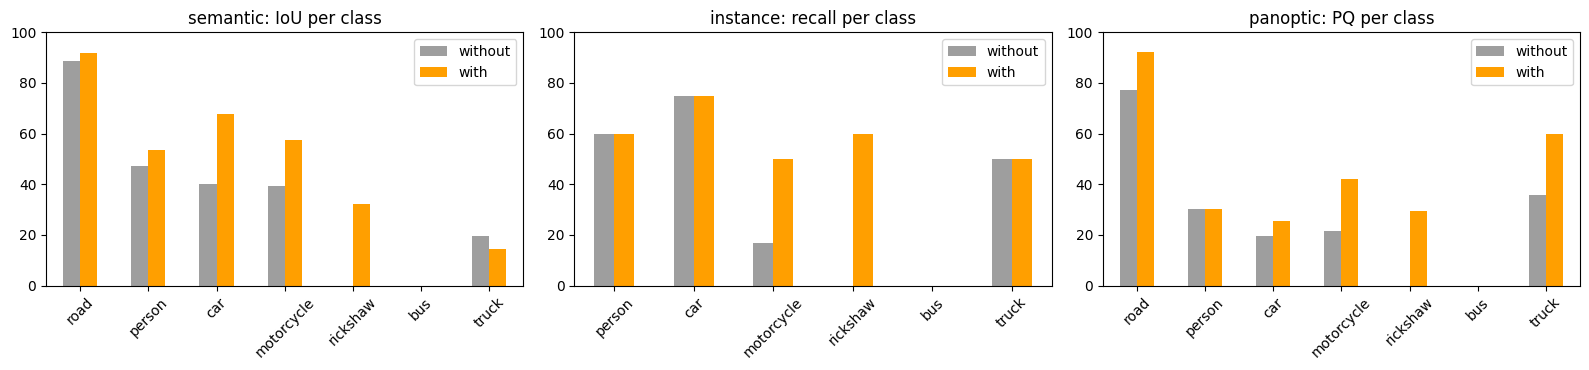

In [21]:
def summary_row(sem, acc, pq):
    # same classes on both sides; a class with labelled objects but no predictions has precision 0
    return [sem[scored].mean(), acc,
            pq.loc[scored_objects, "precision"].fillna(0).mean(), pq.loc[scored_objects, "recall"].mean(),
            pq.loc[scored, "PQ"].mean(), pq.loc[scored, "SQ"].mean(), pq.loc[scored, "RQ"].mean()]

summary = pd.DataFrame({
    "without fine-tuning": summary_row(sem_before, sem_acc_before, pq_before),
    "with fine-tuning": summary_row(sem_after, sem_acc_after, pq_after)},
    index=["semantic: mIoU", "semantic: pixel accuracy", "instance: precision", "instance: recall",
           "panoptic: PQ", "panoptic: SQ", "panoptic: RQ"]).round(1)
summary["change"] = (summary.iloc[:, 1] - summary.iloc[:, 0]).round(1)
print(summary.to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
pd.DataFrame({"without": sem_before, "with": sem_after}).plot.bar(ax=ax[0], rot=45, color=["#9e9e9e", "#ff9f00"])
ax[0].set_title("semantic: IoU per class"); ax[0].set_ylim(0, 100)
pd.DataFrame({"without": pq_before.loc[OBJECTS, "recall"], "with": pq_after.loc[OBJECTS, "recall"]}).plot.bar(
    ax=ax[1], rot=45, color=["#9e9e9e", "#ff9f00"])
ax[1].set_title("instance: recall per class"); ax[1].set_ylim(0, 100)
pd.DataFrame({"without": pq_before.PQ, "with": pq_after.PQ}).plot.bar(ax=ax[2], rot=45, color=["#9e9e9e", "#ff9f00"])
ax[2].set_title("panoptic: PQ per class"); ax[2].set_ylim(0, 100)
plt.tight_layout(); plt.show()

            labelled  without fine-tuning  with fine-tuning
person             5                   16                16
car                4                   61                52
motorcycle         6                    1                 3
rickshaw           5                    0                16
bus                0                    0                 1
truck              2                    3                 1


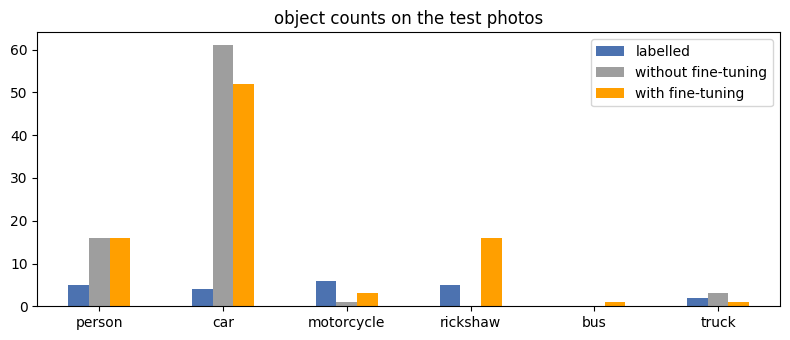

In [22]:
# object counts on the test photos: hand labels vs both versions
cnt = pd.DataFrame({"labelled": [sum(1 for d in test_items for v in d["segments"].values() if v == ID[c]) for c in OBJECTS],
                    "without fine-tuning": [sum(counts(d["pan_before"])[c] for d in test_items) for c in OBJECTS],
                    "with fine-tuning": [sum(counts(d["pan_after"])[c] for d in test_items) for c in OBJECTS]},
                   index=OBJECTS)
print(cnt.to_string())
cnt.plot.bar(figsize=(8, 3.5), rot=0, color=["#4c72b0", "#9e9e9e", "#ff9f00"])
plt.title("object counts on the test photos"); plt.tight_layout(); plt.show()

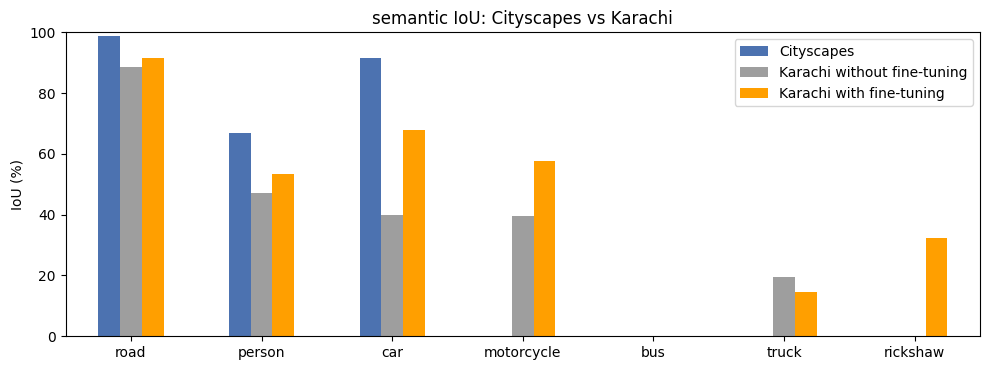

In [23]:
# three stages, semantic IoU on the same classes
shared = ["road", "person", "car", "motorcycle", "bus", "truck"]
stages = pd.DataFrame({"Cityscapes": cs_iou.reindex(shared),
                       "Karachi without fine-tuning": sem_before[shared],
                       "Karachi with fine-tuning": sem_after[shared]})
stages.loc["rickshaw"] = [np.nan, sem_before["rickshaw"], sem_after["rickshaw"]]
stages.plot.bar(figsize=(10, 3.8), rot=0, color=["#4c72b0", "#9e9e9e", "#ff9f00"])
plt.ylabel("IoU (%)"); plt.ylim(0, 100); plt.title("semantic IoU: Cityscapes vs Karachi")
plt.tight_layout(); plt.show()

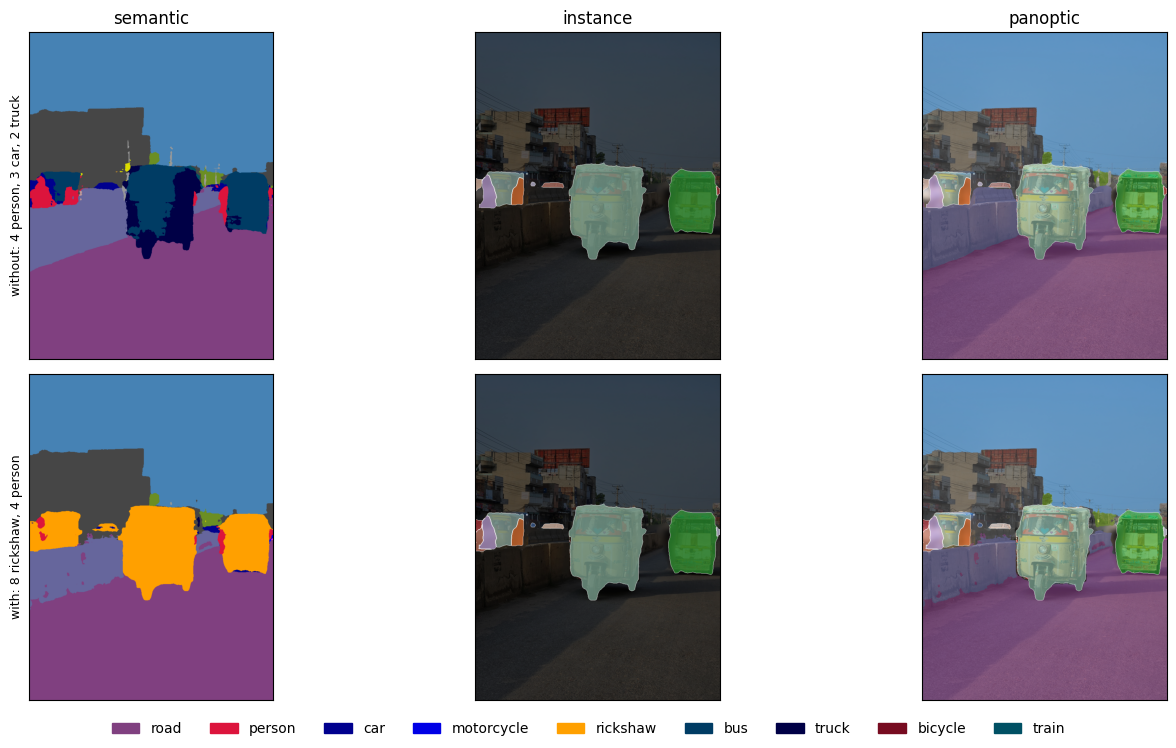

In [24]:
d = max(test_items, key=lambda d: sum(1 for v in d["segments"].values() if v == ID["rickshaw"]))
show_grid([[colorize(d["sem_before"]), draw(d["safe"], d["pan_before"], "instance"), draw(d["safe"], d["pan_before"], "panoptic")],
           [colorize(d["sem_after"]), draw(d["safe"], d["pan_after"], "instance"), draw(d["safe"], d["pan_after"], "panoptic")]],
          ["semantic", "instance", "panoptic"], 5, EVAL + ["bicycle", "train"],
          [f"without: {count_str(d['pan_before'])}", f"with: {count_str(d['pan_after'])}"])

**Comments on the comparison and accuracy**
- **Scores on this split:** semantic mIoU rose by about 14 points, and instance recall by about 19 points. Panoptic PQ rose by about 16 points. These compare the same classes.
- **Instance and panoptic:** most of their masks still come from Mask2Former trained on Cityscapes. SQ rises mainly because rickshaws go from no matched objects to well-fitted ones. Motorcycle SQ falls from 75 to 63, because masks taken from the semantic map are rougher.
- **Object counts:** the count table includes every predicted object. The `predicted` column in the instance tables leaves out objects mostly inside ignored areas, so its numbers are lower. The traffic-jam photo is only partly labelled, so most of the extra cars are real cars without labels, not false detections.
- **Domain gap:** Cityscapes scores higher than Karachi for road, person and car. Motorcycle and truck can't be compared, because they cover only a few pixels in the 8 Cityscapes images and bus has no score there. Fine-tuning on 7 local photos raises most classes on this split.
- **Reliability:** only 4 test photos, with 5 rickshaws, 6 motorbikes and 2 trucks. One object more or less changes a class score by 15-50 points. Bus has no test objects at all. All scores here depend on which photos ended up in test, so treat them as a rough guide.


## 9. Unlabelled Karachi photos

The remaining photos (phone, web and Commons) have no labels, so they can't be scored. They are still compared by class share and object counts. Commons photos are downloaded if they aren't in Drive yet. Only busy-road scenes are kept (at least 15% road and at least 5% vehicles or people), and near-duplicates are dropped.

In [25]:
HEADERS = {"User-Agent": "KarachiRoadSegCoursework/1.0 (student coursework)"}
if not glob.glob(os.path.join(COMMONS_DIR, "*.jpg")):
    os.makedirs(COMMONS_DIR, exist_ok=True)
    rows, k = [], 0
    for q in ["Karachi traffic", "Karachi road", "Karachi street", "Karachi rickshaw"]:
        params = dict(action="query", format="json", generator="search", gsrsearch=q + " filetype:bitmap",
                      gsrnamespace=6, gsrlimit=30, prop="imageinfo", iiprop="url|size|mime|extmetadata", iiurlwidth=1280)
        pages = requests.get("https://commons.wikimedia.org/w/api.php", params=params, headers=HEADERS, timeout=30).json()
        for p in pages.get("query", {}).get("pages", {}).values():
            info = (p.get("imageinfo") or [{}])[0]; meta = info.get("extmetadata", {})
            lic = re.sub("<[^>]+>", "", meta.get("LicenseShortName", {}).get("value", ""))
            if info.get("mime") != "image/jpeg" or not lic.lower().startswith(("cc", "public domain")) or k >= 25:
                continue
            for attempt in range(3):
                r = requests.get(info.get("thumburl") or info["url"], headers=HEADERS, timeout=60)
                if r.status_code != 429:
                    break
                time.sleep(5)
            if r.ok:
                fn = f"commons_{k:02d}.jpg"; open(os.path.join(COMMONS_DIR, fn), "wb").write(r.content); k += 1
                rows.append(dict(file=fn, title=p["title"], licence=lic,
                                 author=re.sub("<[^>]+>", "", meta.get("Artist", {}).get("value", ""))))
            time.sleep(1)
    pd.DataFrame(rows).to_csv(os.path.join(COMMONS_DIR, "credits.csv"), index=False)

labelled = {d["name"] for d in data}
extra_paths = [p for folder in [IMG_DIR, COMMONS_DIR] for e in ("jpg", "jpeg", "png", "webp")
               for p in glob.glob(os.path.join(folder, f"*.{e}")) if os.path.basename(p) not in labelled]

MOVING = [ID[c] for c in ["person", "car", "truck", "bus", "train", "motorcycle", "bicycle"]]
cands, seen = [], []
for p in sorted(extra_paths):
    try:
        img = load_clean(p)
    except Exception:
        continue
    t = thumb(img)
    if any(t @ s / len(t) > 0.9 for s in seen):
        continue
    seen.append(t)
    a = semantic(base, img)
    cands.append(dict(name=os.path.basename(p), img=img, before=a,
                      road=(a == ID["road"]).mean(), busy=np.isin(a, MOVING).mean()))

extra = [e for e in cands if e["road"] >= 0.15 and e["busy"] >= 0.05]
if len(extra) < 4:
    extra = sorted(cands, key=lambda e: e["road"] + e["busy"], reverse=True)[:8]
for e in extra:
    e["after"] = semantic(ft, e["img"])
    e["pan_before"] = panoptic(e["img"])
    e["pan_after"] = relabel(e["pan_before"], e["after"])
    e["safe"] = anon(e["img"], e["before"], e["after"], segs=e["pan_before"])
print(len(extra), "busy-road photos kept from", len(cands), "unique unlabelled photos")

16 busy-road photos kept from 65 unique unlabelled photos


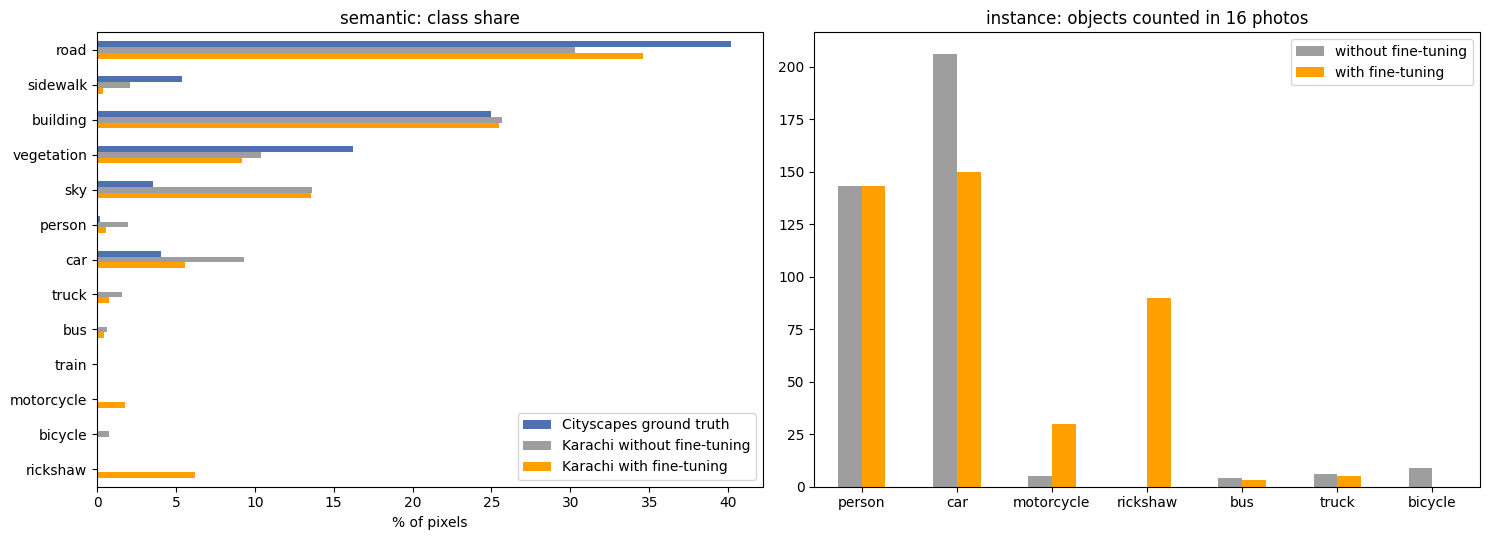

            without fine-tuning  with fine-tuning
person                      143               143
car                         206               150
motorcycle                    5                30
rickshaw                      0                90
bus                           4                 3
truck                         6                 5
bicycle                       9                 0


In [26]:
share = lambda segs: pd.DataFrame([np.bincount(s.ravel(), minlength=len(CLASSES)) / s.size * 100 for s in segs],
                                  columns=CLASSES).mean()
cmp = pd.DataFrame({"Cityscapes ground truth": gt_share.reindex(CLASSES).fillna(0),
                    "Karachi without fine-tuning": share([e["before"] for e in extra]),
                    "Karachi with fine-tuning": share([e["after"] for e in extra])})
show = ["road", "sidewalk", "building", "vegetation", "sky", "person", "car", "truck", "bus",
        "train", "motorcycle", "bicycle", "rickshaw"]
obj_cnt = pd.DataFrame({"without fine-tuning": [sum(counts(e["pan_before"])[c] for e in extra) for c in OBJECTS + ["bicycle"]],
                        "with fine-tuning": [sum(counts(e["pan_after"])[c] for e in extra) for c in OBJECTS + ["bicycle"]]},
                       index=OBJECTS + ["bicycle"])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
cmp.loc[show].plot.barh(ax=ax[0], color=["#4c72b0", "#9e9e9e", "#ff9f00"])
ax[0].invert_yaxis(); ax[0].set_xlabel("% of pixels"); ax[0].set_title("semantic: class share")
obj_cnt.plot.bar(ax=ax[1], rot=0, color=["#9e9e9e", "#ff9f00"])
ax[1].set_title(f"instance: objects counted in {len(extra)} photos")
plt.tight_layout(); plt.show()
print(obj_cnt.to_string())

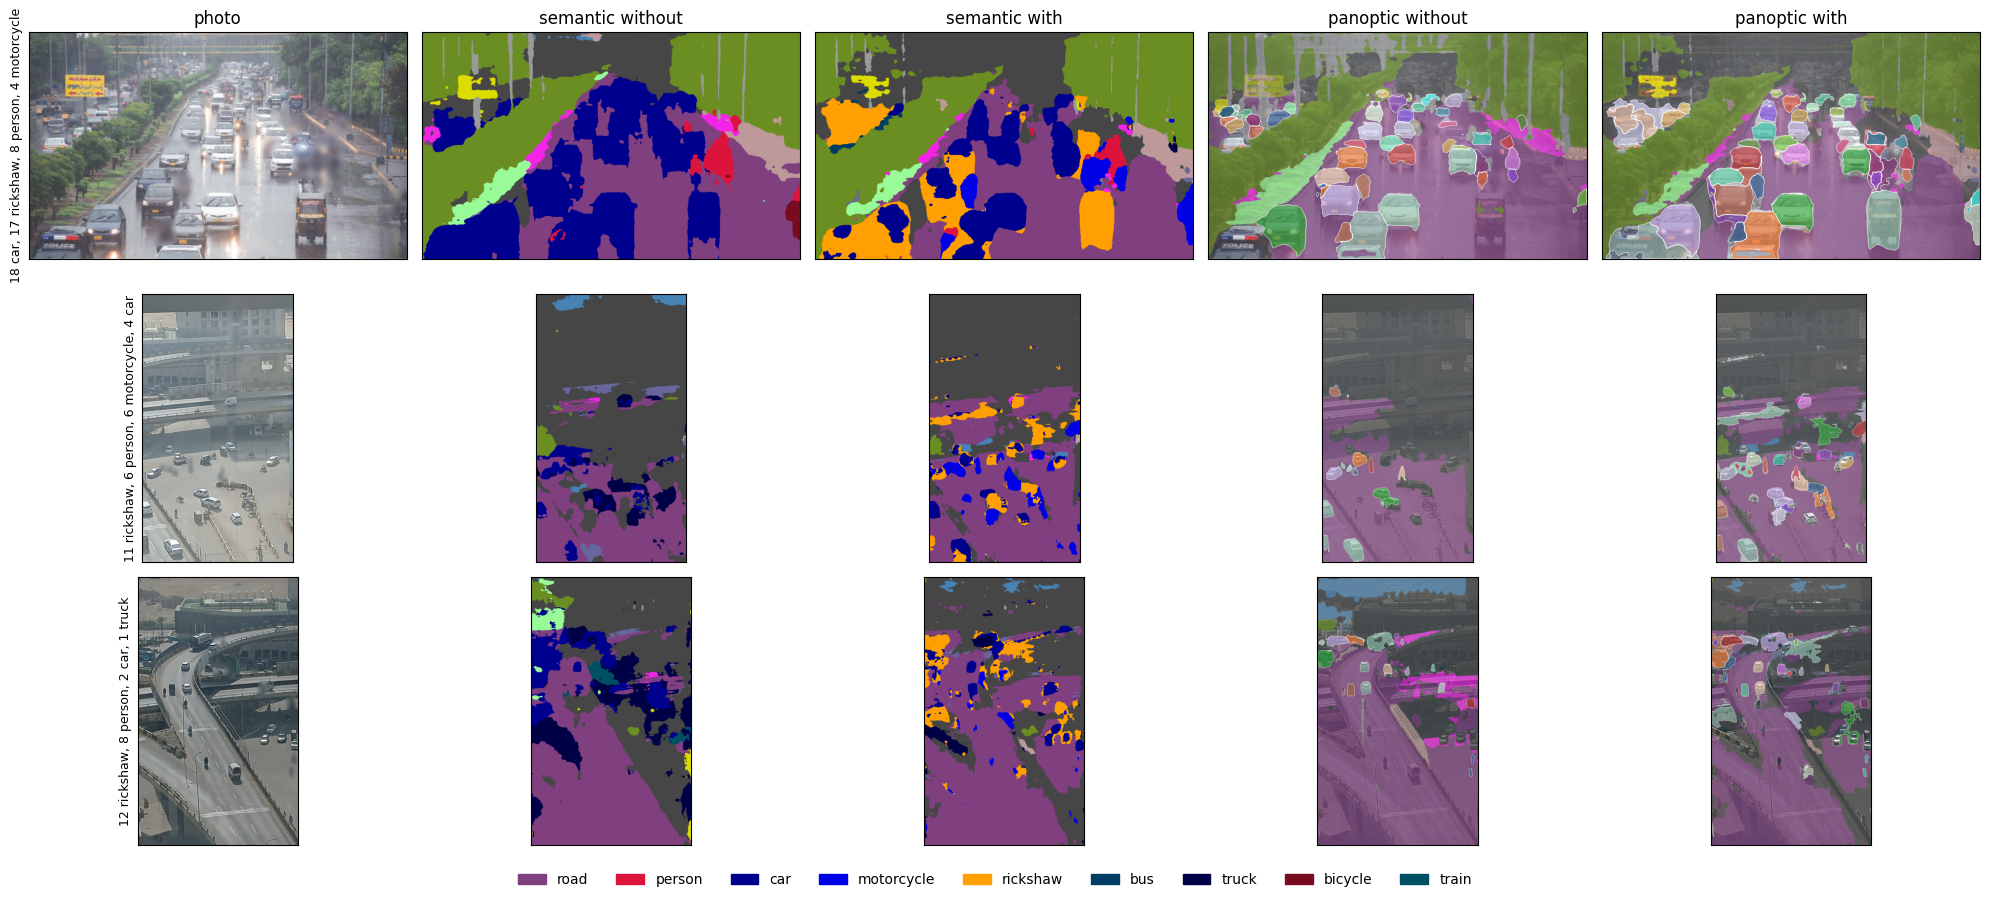

In [27]:
top = sorted(extra, key=lambda e: counts(e["pan_after"])["rickshaw"] + counts(e["pan_after"])["motorcycle"], reverse=True)[:3]
show_grid([[e["safe"], colorize(e["before"]), colorize(e["after"]), draw(e["safe"], e["pan_before"], "panoptic"),
            draw(e["safe"], e["pan_after"], "panoptic")] for e in top],
          ["photo", "semantic without", "semantic with", "panoptic without", "panoptic with"], 4,
          EVAL + ["bicycle", "train"], [count_str(e["pan_after"]) for e in top])

Compared with Cityscapes, the Karachi photos have less sidewalk and vegetation and more vehicles and people per image. After fine-tuning, bicycle predictions disappear, and rickshaws and motorcycles appear as counted objects. These counts are not scored. The test photos show that rickshaws are over-predicted, so treat 90 rickshaws as an upper estimate.

## 10. Conclusions

- **Cityscapes:** 50 cities, but almost all German, recorded the same way and labelled with the same classes. It provides semantic, instance and panoptic labels, and a model trained on it learns one kind of street.
- **Without fine-tuning:** road transfers well to Karachi (about 89% IoU on the test photos). Vehicles don't, especially rickshaws (no class) and motorbikes (rare in Cityscapes).
- **With fine-tuning:** 7 hand-labelled training photos and a new rickshaw class raise semantic mIoU from about 39% to about 53% on the 4 test photos. This is a small test set, so the gain is only a rough guide.
- **Partial transfer:** fine-tuning the semantic model transfers only partly to instance and panoptic segmentation. It improves object classes and adds some missed objects, but most masks are not retrained.
- **Limits:** a small number of labelled photos, too few buses, loaders confused with rickshaws, haze predicted as road, Mask2Former masks that are not retrained, and number plates that are not blurred.


## Appendix: share the model on Hugging Face

Only needed after retraining (`RETRAIN = True`). Set `UPLOAD_TO_HF = True`, run the cell, and paste a token with **Write** access from huggingface.co/settings/tokens. This replaces the model at `HF_MODEL`.


In [28]:
UPLOAD_TO_HF = False

if UPLOAD_TO_HF:
    assert os.path.isdir(SAVED_MODEL), "No new model to upload: set RETRAIN = True and run section 6 first"
    from huggingface_hub import login, HfApi
    login()
    api = HfApi()
    api.create_repo(HF_MODEL, exist_ok=True)
    api.upload_folder(folder_path=SAVED_MODEL, repo_id=HF_MODEL)
    print("uploaded to", f"https://huggingface.co/{HF_MODEL}")
